# 05 — ARIMA Models

In [1]:
packages = c("astsa", "zoo")
missing = packages[!sapply(packages, requireNamespace, quietly=TRUE)]
if (length(missing) > 0) install.packages(missing, repos="https://cloud.r-project.org")
library(astsa)
library(zoo)
options(digits=5)
par(mfrow=c(1,1))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




## Integrated models and differencing

**Integrated** means that differences of the observed series are modeled as stationary ARMA data. **Differencing** measures change between observations. **Lag** means the number of time steps separating two values. The **backshift operator** $B$ sends $x_t$ to $x_{t-1}$.

$$\nabla x_t=(1-B)x_t=x_t-x_{t-1},\qquad \nabla^2x_t=x_t-2x_{t-1}+x_{t-2}.$$

An $\operatorname{ARIMA}(p,d,q)$ process satisfies

$$\phi(B)(1-B)^d x_t=\alpha+\theta(B)w_t,$$

where $p$ is the nonseasonal autoregressive order, $d$ the difference order, $q$ the moving-average order, $\phi(B)=1-\sum_{j=1}^{p}\phi_jB^j$, $\theta(B)=1+\sum_{k=1}^{q}\theta_k B^k$, and $w_t$ is white noise with variance $\sigma_w^2$. A **white-noise innovation** is a zero-mean, serially uncorrelated shock; Gaussian white noise additionally has a normal distribution.

If $\delta=E(\nabla^dx_t)$, then $\alpha=\delta(1-\sum_j\phi_j)$. A nonzero drift can matter when fitting differenced data.

### Equivalent model specifications: glacial varves

The MA(1) model for the first differences of log thickness is the same integrated specification as ARIMA(0,1,1) for log thickness:

$$y_t=\nabla\log x_t,\qquad y_t=w_t+\theta_1w_{t-1}.$$

The fitted coefficient $\hat\theta_1$ measures the effect of the previous innovation on the current transformed value. The innovation variance $\hat\sigma_w^2$ is measured in squared log-difference units. The comparison below checks model equivalence; `sarima()` also generates diagnostic graphs.

initial  value -0.551778 
iter   2 value -0.671626
iter   3 value -0.705973
iter   4 value -0.707314
iter   5 value -0.722372
iter   6 value -0.722738
iter   7 value -0.723187
iter   8 value -0.723194
iter   9 value -0.723195
iter   9 value -0.723195
iter   9 value -0.723195
final  value -0.723195 
converged
initial  value -0.722700 
iter   2 value -0.722702
iter   3 value -0.722702
iter   3 value -0.722702
iter   3 value -0.722702
final  value -0.722702 
converged
<><><><><><><><><><><><><><>
 
Coefficients: 
    Estimate     SE t.value p.value
ma1  -0.7705 0.0341 -22.616       0

sigma^2 estimated as 0.23532 on 632 degrees of freedom 
 
AIC = 1.3988  AICc = 1.3988  BIC = 1.4129 
 
initial  value -0.551778 
iter   2 value -0.671626
iter   3 value -0.705973
iter   4 value -0.707314
iter   5 value -0.722372
iter   6 value -0.722738
iter   7 value -0.723187
iter   8 value -0.723194
iter   9 value -0.723195
iter   9 value -0.723195
iter   9 value -0.723195
final  value -0.723195 
converge

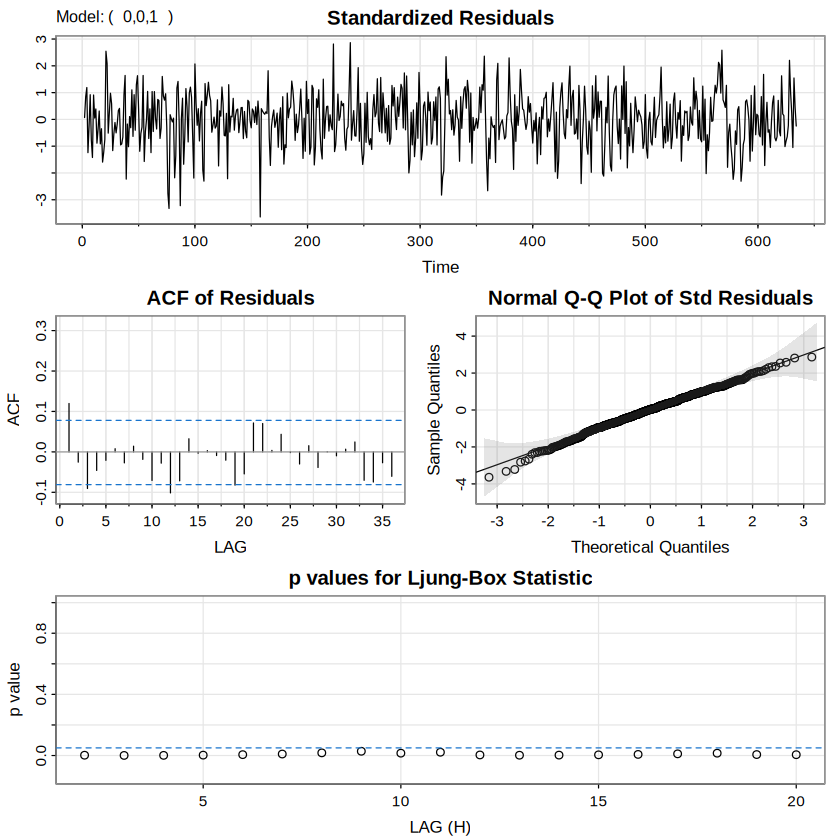

     ma1 
-0.77054 
     ma1 
-0.77054 
 diff_var arima_var 
  0.23532   0.23532 


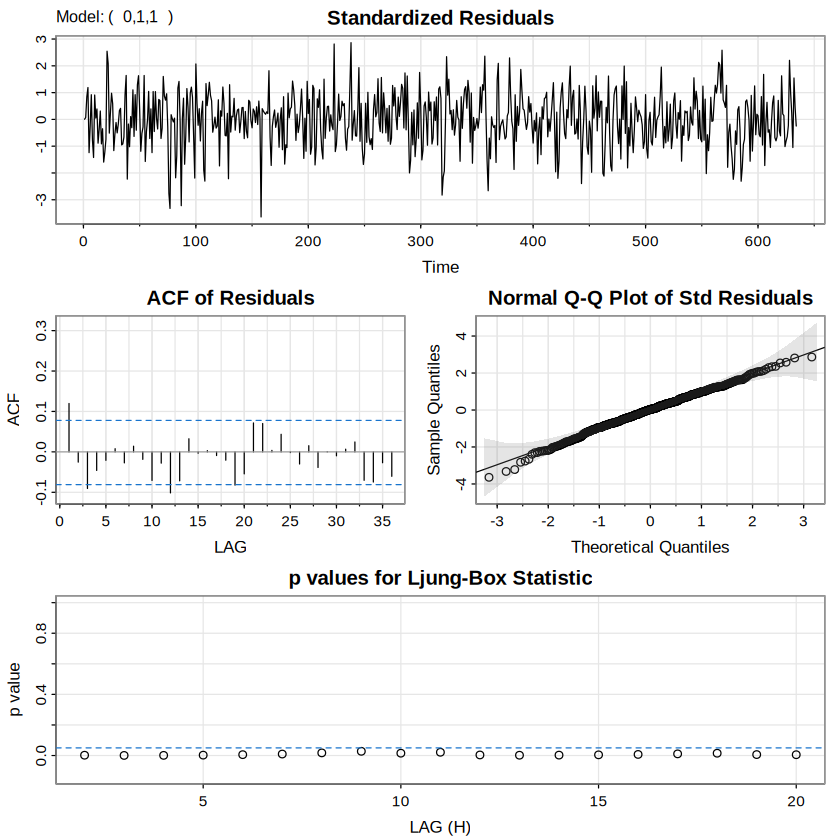

In [2]:
fit_v_diff = sarima(diff(log(varve)), p=0, d=0, q=1, no.constant=TRUE)
fit_v_arima = sarima(log(varve), p=0, d=1, q=1, no.constant=TRUE)
# Compare coefficient and innovation variance estimates
print(fit_v_diff$fit$coef)
print(fit_v_arima$fit$coef)
print(c(diff_var=fit_v_diff$fit$sigma2, arima_var=fit_v_arima$fit$sigma2))

**Interpretation:** The two fitted specifications return the same MA coefficient, **−0.77054**, and innovation variance, **0.23532**, in the recorded output. This verifies the equivalence between fitting MA(1) to $\nabla\log(x_t)$ and fitting ARIMA(0,1,1) to $\log(x_t)$. The first forecasts log *changes*; the second forecasts log *levels*. Exponentiating the predicted log value gives a conditional median on the original thickness scale, not generally its conditional mean.

## Forecasts for integrated models

A **forecast horizon** $m$ means $m$ future time steps beyond the final observation $x_n$. A **prediction error** is actual minus predicted value. **MSPE** is mean squared prediction error; its square root is the forecast standard error.

For $y_t=\nabla x_t$, reconstruct level forecasts recursively:

$$\widehat{x}_{n+m\mid n}=\widehat{x}_{n+m-1\mid n}+\widehat{y}_{n+m\mid n},\qquad\widehat{x}_{n\mid n}=x_n.$$

For an integrated causal-shock representation $\psi(z)=\theta(z)/[\phi(z)(1-z)^d]$, an approximate forecast MSPE is

$$P_{n+m\mid n}\approx \sigma_w^2\sum_{j=0}^{m-1}\psi_j^2.$$

Here $\psi_j$ measures the effect of innovation $w_{t-j}$ on $x_t$; persistence of these weights governs forecast uncertainty.

### Random walk with drift

$$x_t=x_{t-1}+\delta+w_t,\qquad w_t\sim\operatorname{WN}(0,\sigma_w^2).$$

By summing the changes, $x_{n+m}=x_n+m\delta+\sum_{j=1}^{m}w_{n+j}$. Therefore,

$$\widehat x_{n+m\mid n}=x_n+m\delta,\quad P_{n+m\mid n}=m\sigma_w^2,\quad \operatorname{SE}_m=\sqrt{m}\sigma_w.$$

**Drift** $\delta$ is the expected change per period, not the level. **Uncertainty widens:** forecast variance grows linearly with horizon; forecast standard error grows with $\sqrt m$.

   horizon expected_change MSPE forecast_SE
1        1             0.3    1      1.0000
2        2             0.6    2      1.4142
3        3             0.9    3      1.7321
4        4             1.2    4      2.0000
5        5             1.5    5      2.2361
6        6             1.8    6      2.4495
7        7             2.1    7      2.6458
8        8             2.4    8      2.8284
9        9             2.7    9      3.0000
10      10             3.0   10      3.1623
11      11             3.3   11      3.3166
12      12             3.6   12      3.4641
 [1] 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1


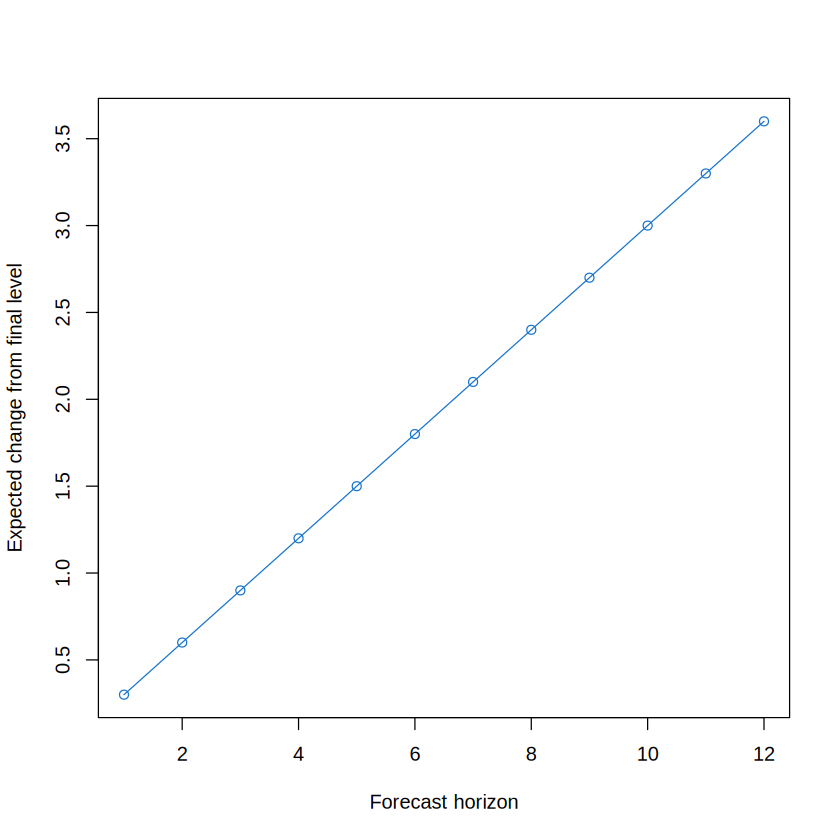

In [3]:
delta = .3
sigma_w = 1
m = 1:12
rw_results = data.frame(horizon=m, expected_change=m*delta,
                        MSPE=m*sigma_w^2, forecast_SE=sqrt(m)*sigma_w)
print(rw_results)
plot(m, rw_results$expected_change, type="o", col=4,
     xlab="Forecast horizon", ylab="Expected change from final level")
# Coefficients are all one for a unit-root random walk
print(ARMAtoMA(ar=1, ma=0, 20))

**Interpretation:** With drift 0.3 per step and innovation SD 1, the expected change at horizon 12 is 3.6, while its forecast standard error is about 3.46. Even if the expected path rises, forecast uncertainty grows. The `ARMAtoMA()` output consists of ones, rather than decaying weights: this is the unit-root signature.

### ARIMA(1,1,0): out-of-sample forecasting

$$\nabla x_t=0.9\nabla x_{t-1}+w_t\quad\Longleftrightarrow\quad x_t=1.9x_{t-1}-0.9x_{t-2}+w_t.$$

The *differences* are stationary when $|0.9|<1$, but the levels remain integrated. An apparent AR(2) equation in levels does not make the level series stationary. The fitted forecast and gray intervals should be compared to withheld observations (101–150).

[1]  1.9  2.7  3.4  4.1  4.7  5.2  5.7  6.1  6.5  6.9  7.2  7.5  7.7  7.9  8.1
[16]  8.3  8.5  8.6  8.8  8.9  9.0  9.1  9.2  9.3  9.4  9.4  9.5  9.5  9.6  9.6
[31]  9.7  9.7  9.7  9.7  9.8  9.8  9.8  9.8  9.9  9.9  9.9  9.9  9.9  9.9  9.9
[46]  9.9  9.9  9.9  9.9 10.0 10.0 10.0 10.0 10.0 10.0 10.0 10.0 10.0 10.0 10.0

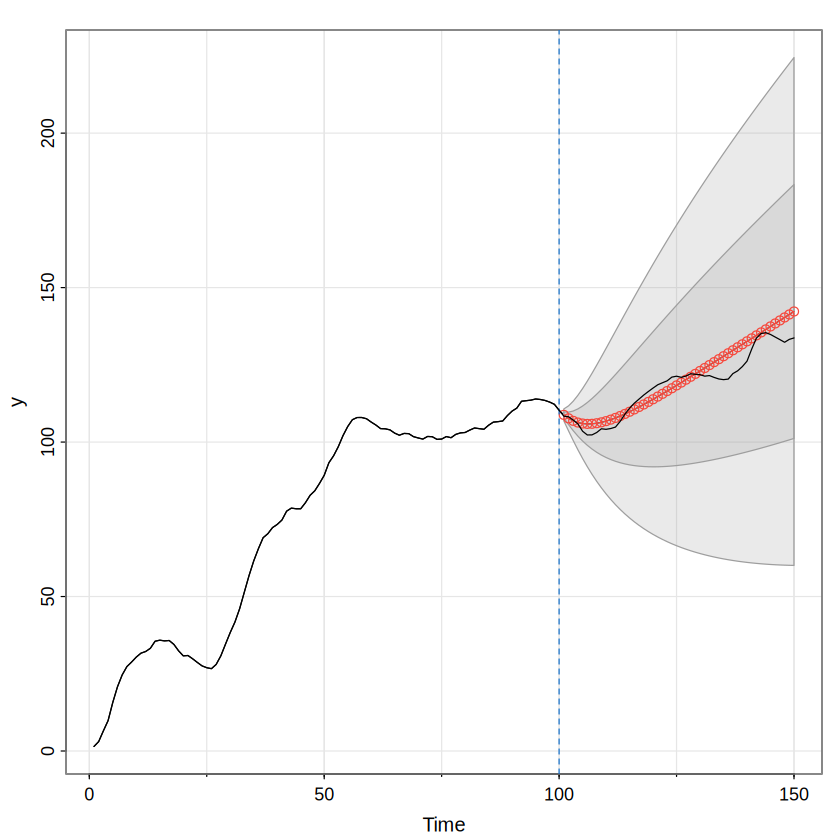

In [4]:
round(ARMAtoMA(ar=c(1.9,-.9), ma=0, 60), 1)
set.seed(1998)
x = ts(arima.sim(list(order=c(1,1,0), ar=.9), n=150)[-1])
y = window(x, start=1, end=100)
forecast_arima110 = sarima.for(y, n.ahead=50, p=1, d=1, q=0, plot.all=TRUE)
abline(v=100, lty=2, col=4)
lines(x)

**Graph interpretation:** The vertical separator indicates the end of training data at observation 100; observations after it are genuine holdout values. Forecast bands widen as the horizon increases because the level process is integrated. Check where withheld values fall relative to the bands; fitting the training series closely is not the same as making accurate long-range forecasts. The printed MA-infinity weights approach 10, not zero, confirming nonstationarity of levels.

### IMA(1,1) and exponentially weighted moving average (EWMA)

An IMA(1,1) is ARIMA(0,1,1). Using the negative MA coefficient convention,

$$x_t=x_{t-1}+w_t-\lambda w_{t-1},\qquad\alpha=1-\lambda.$$

**EWMA** updates the next forecast as a weighted average of the latest observation and the previous one-step forecast:

$$\widehat x_{n+1\mid n}=\alpha x_n+(1-\alpha)\widehat x_{n\mid n-1}.$$

The smoothing coefficient $\alpha$ is between 0 and 1. Larger $\alpha$ responds more to recent observations; smaller $\alpha$ smooths more. With $\lambda=1-\alpha$,

$$P_{n+m\mid n}\approx\sigma_w^2\left[1+(m-1)\alpha^2\right].$$

Holt-Winters exponential smoothing without trend and without seasonal component.

Call:
HoltWinters(x = x_ima, beta = FALSE, gamma = FALSE)

Smoothing parameters:
 alpha: 0.16631
 beta : FALSE
 gamma: FALSE

Coefficients:
     [,1]
a -2.2415

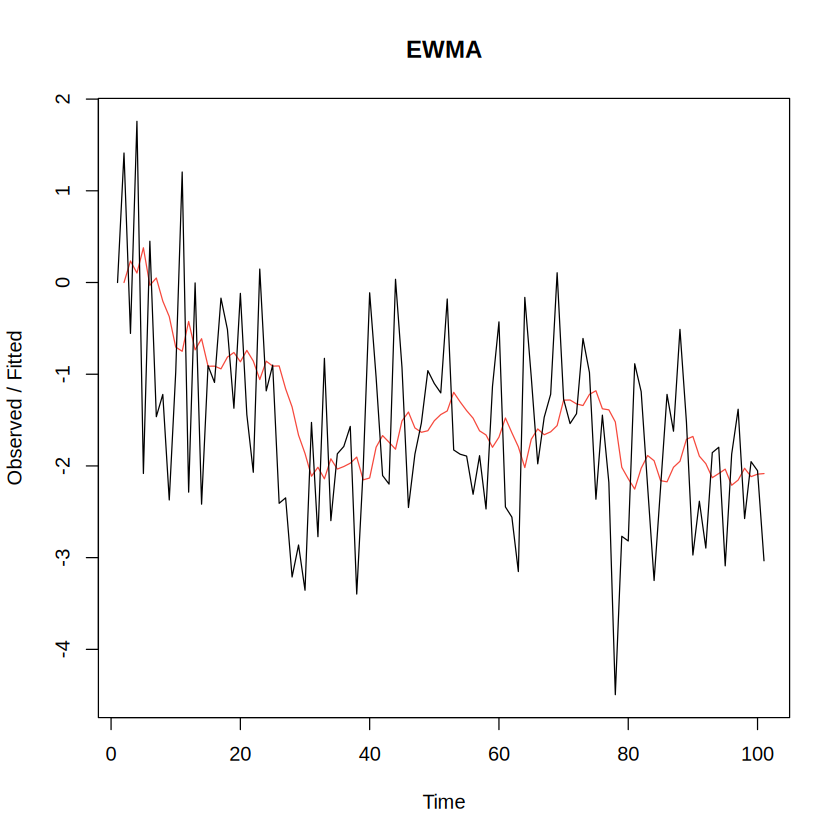

In [5]:
set.seed(666)
x_ima = arima.sim(list(order=c(0,1,1), ma=-.8), n=100)
(x_ima_fit = HoltWinters(x_ima, beta=FALSE, gamma=FALSE))
plot(x_ima_fit, main="EWMA")

**Interpretation:** `HoltWinters()` estimates `alpha` rather than forcing it to 0.2. Compare the printed estimate with 0.2 and inspect how the smoothed fitted line tracks changes. The model is a level-only smoother (`beta=FALSE`, `gamma=FALSE`): it does not include a separate estimated trend or seasonality. The supplied example reports estimated alpha ≈ 0.1663; use the value from the executed output if it differs.

## Building and checking an ARIMA model: quarterly GNP

**Log growth** is $g_t=\log(y_t)-\log(y_{t-1})\approx (y_t-y_{t-1})/y_{t-1}$ for small changes. Its unit is a log change per quarter, approximately a fractional quarterly growth rate. A slowly decaying ACF of the original level and a more stable differenced series are evidence to consider $d=1$, not formal proof of stationarity.

**ACF** measures correlation with lagged values; **PACF** removes linear effects of intermediate lags. ACF cut-off after lag $q$ suggests MA($q$); PACF cut-off after lag $p$ suggests AR($p$). These are guides, not guarantees.

[1] 0.99 0.97 0.96 0.94 0.93 0.91 0.90 0.88 0.87 0.85 0.83 0.82 0.80 0.79 0.77
[16] 0.76 0.74 0.73 0.72 0.70 0.69 0.68 0.66 0.65 0.64

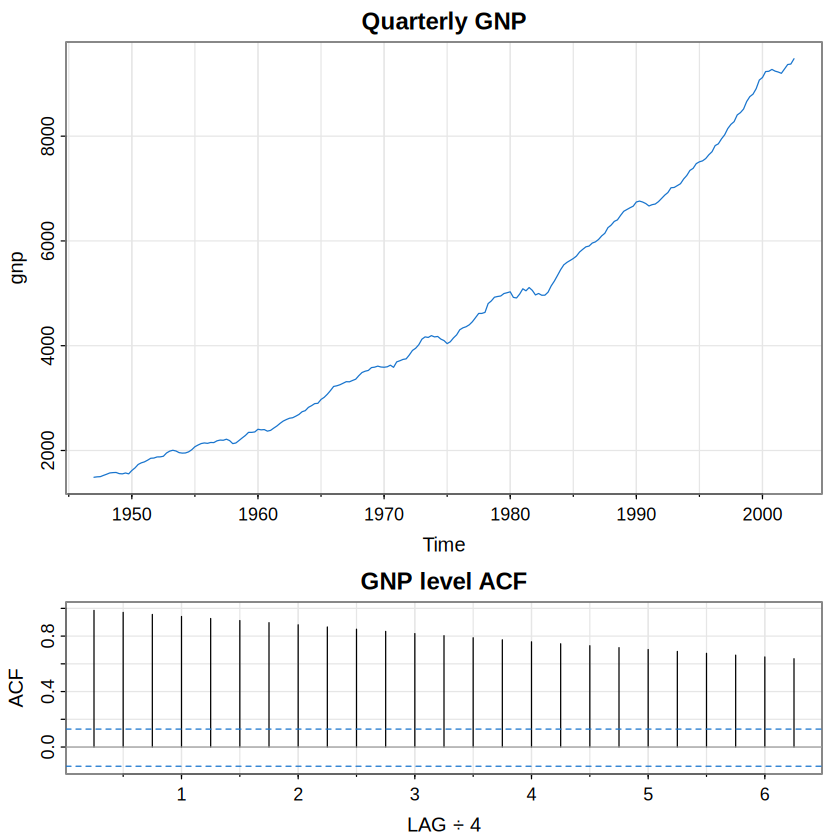

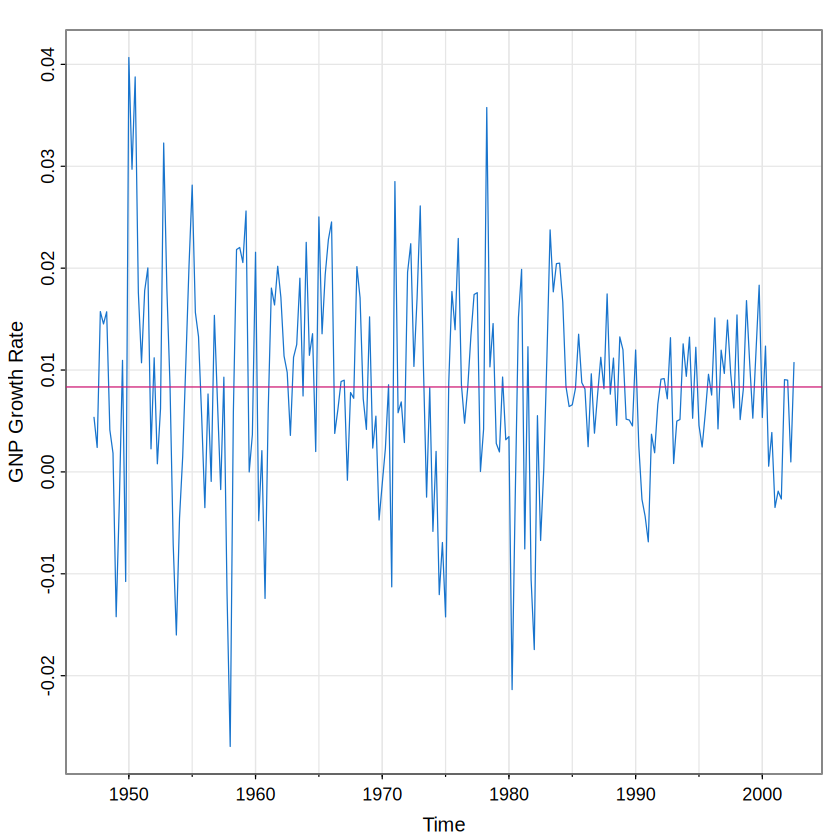

ACF,0.35,0.19,-0.01,-0.12,-0.17,-0.11,-0.09,-0.04,0.04,0.05,⋯,0.05,0.07,0.10,0.06,0.07,-0.09,-0.05,-0.10,-0.05,0.00
PACF,0.35,0.08,-0.11,-0.12,-0.09,0.01,-0.03,-0.02,0.05,0.01,⋯,0.10,0.00,0.02,-0.04,0.01,-0.11,0.03,-0.03,0.00,0.01


Mean quarterly log growth: 0.0083375 
Approximate percent growth: 0.83375 %


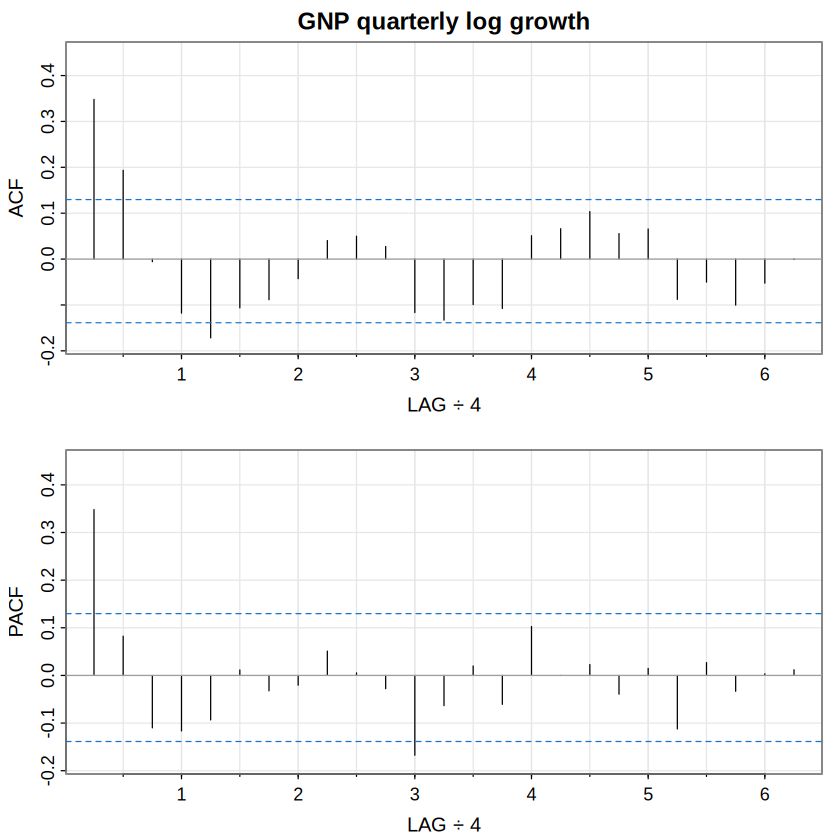

In [6]:
layout(1:2, heights=2:1)
tsplot(gnp, col=4, main="Quarterly GNP")
acf1(gnp, main="GNP level ACF")
par(mfrow=c(1,1))
growth = diff(log(gnp))
tsplot(growth, ylab="GNP Growth Rate", col=4)
abline(h=mean(growth), col=6)
acf2(growth, main="GNP quarterly log growth")
cat("Mean quarterly log growth:", mean(growth), "
")
cat("Approximate percent growth:", 100*mean(growth), "%
")

**Graph interpretation:** GNP levels rise strongly and their ACF decays slowly, whereas quarterly log differences oscillate around a more stable mean. The calculated mean quarterly log growth is **0.0083375**, corresponding to approximately **0.834%** for small changes (exact compounded change $100[\exp(0.0083375)-1]\approx0.837\%$). Because `gnp` is quarterly, ACF/PACF plot-axis lag 1 represents **one year (four quarters)**. The first few *quarterly* lags, rather than the first few years, matter when suggesting small $p$ and $q$.

### Compare MA(2) and AR(1) on GNP growth

$$\text{MA(2):}\quad g_t=\mu+w_t+\theta_1w_{t-1}+\theta_2w_{t-2},$$

$$\text{AR(1):}\quad g_t=\mu+\phi(g_{t-1}-\mu)+w_t.$$

The R output `xmean` is the **unconditional mean** $\mu$; in the AR(1) equation the intercept is $(1-\phi)\mu$. A positive mean growth implies a nonzero drift in log GNP. In both models the MA/AR coefficients describe shock persistence, not percentage growth directly.

initial  value -4.591629 
iter   2 value -4.661095
iter   3 value -4.662220
iter   4 value -4.662243
iter   5 value -4.662243
iter   6 value -4.662243
iter   6 value -4.662243
iter   6 value -4.662243
final  value -4.662243 
converged
initial  value -4.662022 
iter   2 value -4.662023
iter   2 value -4.662023
iter   2 value -4.662023
final  value -4.662023 
converged
<><><><><><><><><><><><><><>
 
Coefficients: 
      Estimate     SE t.value p.value
ma1     0.3028 0.0654  4.6272  0.0000
ma2     0.2035 0.0644  3.1594  0.0018
xmean   0.0083 0.0010  8.7178  0.0000

sigma^2 estimated as 8.9192e-05 on 219 degrees of freedom 
 
AIC = -6.4501  AICc = -6.4496  BIC = -6.3888 
 
initial  value -4.589567 
iter   2 value -4.654150
iter   3 value -4.654150
iter   4 value -4.654151
iter   4 value -4.654151
iter   4 value -4.654151
final  value -4.654151 
converged
initial  value -4.655919 
iter   2 value -4.655921
iter   3 value -4.655922
iter   4 value -4.655922
iter   5 value -4.655922
iter   5 va

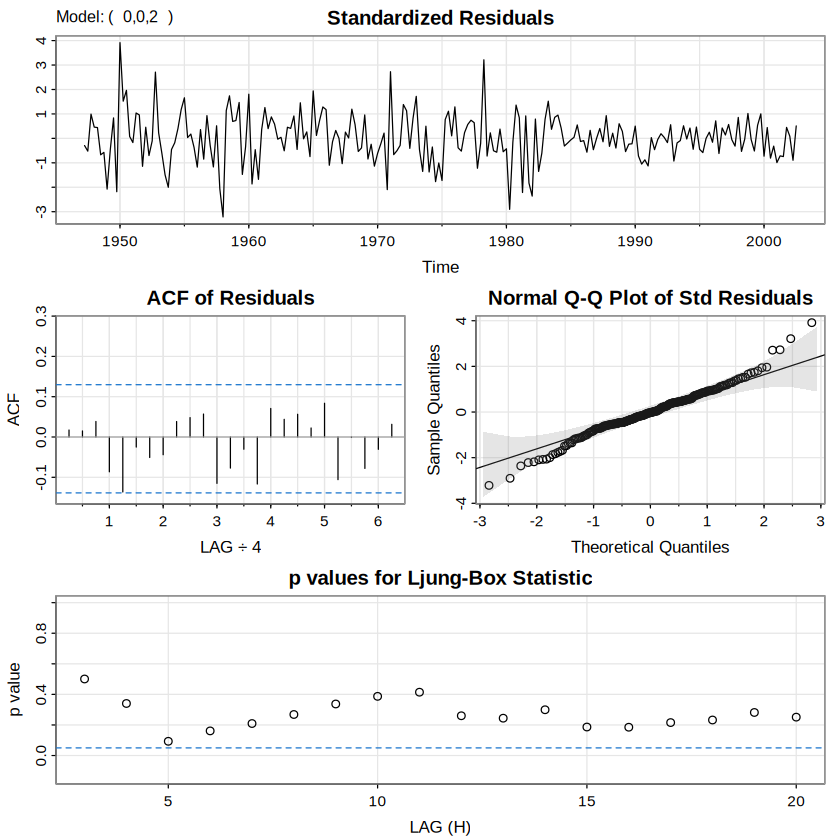

MA(2) coefficients:
      ma1       ma2     xmean 
0.3028085 0.2035189 0.0083267 
AR(1) coefficients:
     ar1    xmean 
0.346654 0.008336 
AR(1) approximated MA weights:
 [1] 0.350 0.122 0.043 0.015 0.005 0.002 0.001 0.000 0.000 0.000


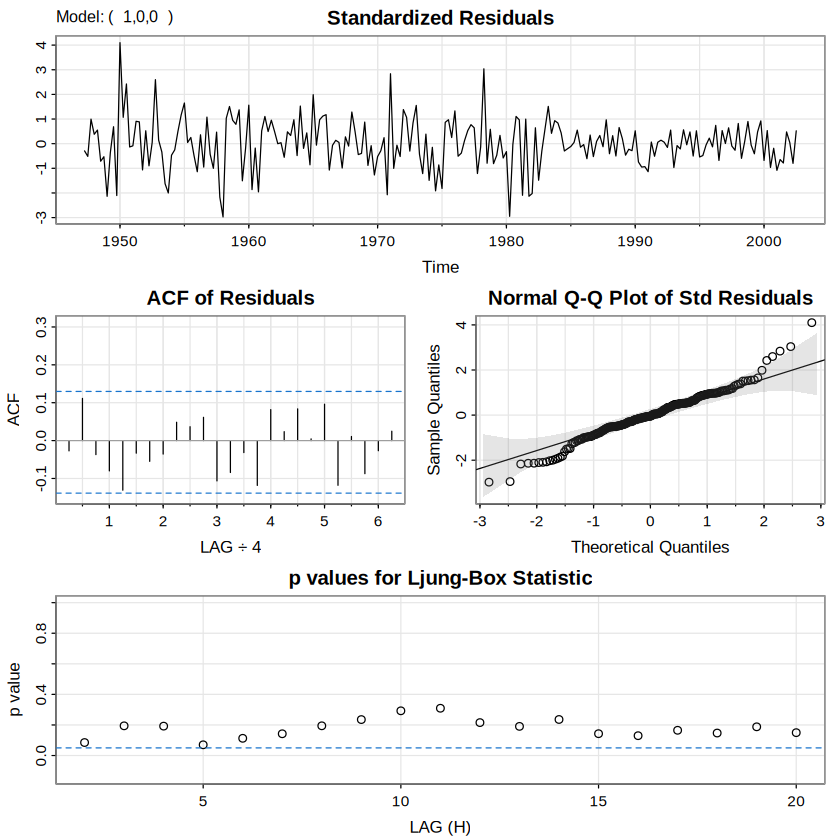

In [7]:
fit_gnp_ma2 = sarima(growth, 0,0,2)
fit_gnp_ar1 = sarima(growth, 1,0,0)
cat("MA(2) coefficients:
"); print(fit_gnp_ma2$fit$coef)
cat("AR(1) coefficients:
"); print(fit_gnp_ar1$fit$coef)
cat("AR(1) approximated MA weights:
")
print(round(ARMAtoMA(ar=.35, ma=0, 10),3))

**Interpretation:** MA(2) estimates are $\hat\theta_1=0.3028$, $\hat\theta_2=0.2035$, and $\hat\mu=0.00833$. The AR(1) fit gives $\hat\phi=0.3467$ and essentially the same mean. Both models describe modest short-lag positive dependence in GNP growth. For AR(1), the implied shock weights begin $0.347$, $0.120$, $0.042$, then decay, which explains the similarity to a low-order MA approximation. The MA estimates have recorded p-values below 0.01; this assesses coefficients conditional on the fitted model, **not** the adequacy of the residuals.

### Residual diagnostics and model choice

A **standardized innovation** is a one-step prediction error divided by its estimated standard deviation. A good model should leave residuals without systematic temporal structure. The **Ljung–Box statistic** summarizes squared sample residual autocorrelations:

$$Q(H)=n(n+2)\sum_{h=1}^{H}\frac{\widehat\rho_e(h)^2}{n-h}.$$

Under suitable conditions, with $p+q$ parameters consumed by the fitted ARMA component, compare to approximately $\chi^2_{H-p-q}$. **Null hypothesis:** no residual autocorrelation through the examined lags. A p-value above 0.05 means insufficient evidence against that null; it does **not prove** residual independence or normality. The Q–Q plot checks marginal normality separately.

initial  value -4.591629 
iter   2 value -4.661095
iter   3 value -4.662220
iter   4 value -4.662243
iter   5 value -4.662243
iter   6 value -4.662243
iter   6 value -4.662243
iter   6 value -4.662243
final  value -4.662243 
converged
initial  value -4.662022 
iter   2 value -4.662023
iter   2 value -4.662023
iter   2 value -4.662023
final  value -4.662023 
converged
<><><><><><><><><><><><><><>
 
Coefficients: 
      Estimate     SE t.value p.value
ma1     0.3028 0.0654  4.6272  0.0000
ma2     0.2035 0.0644  3.1594  0.0018
xmean   0.0083 0.0010  8.7178  0.0000

sigma^2 estimated as 8.9192e-05 on 219 degrees of freedom 
 
AIC = -6.4501  AICc = -6.4496  BIC = -6.3888 
 
initial  value -4.591629 
iter   2 value -4.660639
iter   3 value -4.665404
iter   4 value -4.665858
iter   5 value -4.665953
iter   6 value -4.665955
iter   7 value -4.665956
iter   8 value -4.665956
iter   8 value -4.665956
iter   8 value -4.665956
final  value -4.665956 
converged
initial  value -4.665676 
iter   2 va

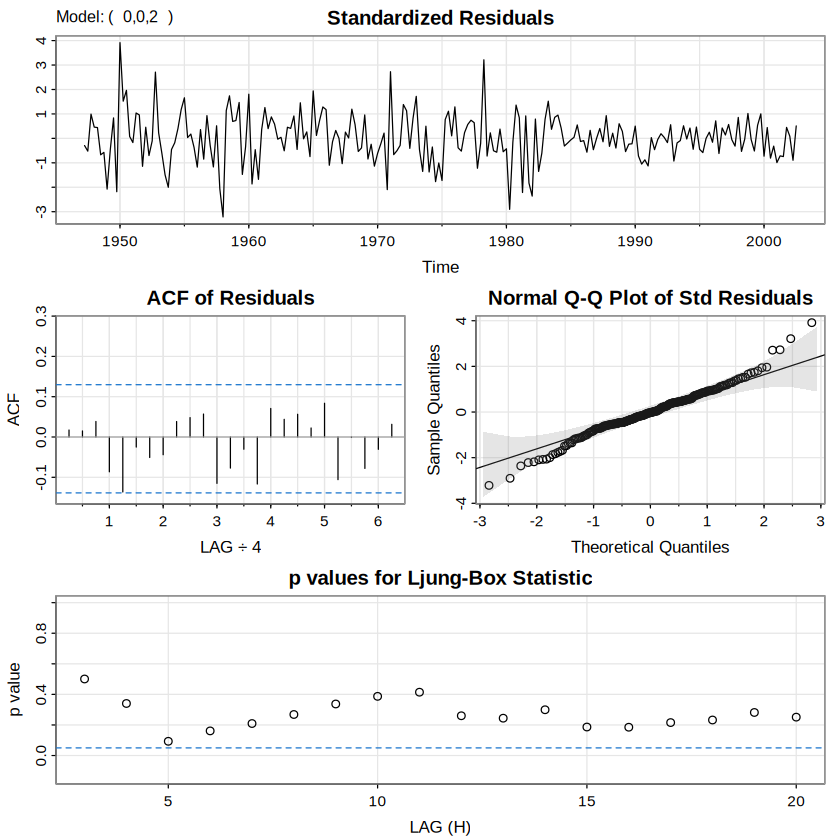

initial  value -4.588072 
iter   2 value -4.647096
iter   3 value -4.655676
iter   4 value -4.655896
iter   5 value -4.655903
iter   6 value -4.655903
iter   7 value -4.655904
iter   7 value -4.655904
iter   7 value -4.655904
final  value -4.655904 
converged
initial  value -4.659296 
iter   2 value -4.659300
iter   3 value -4.659306
iter   4 value -4.659307
iter   5 value -4.659307
iter   5 value -4.659307
iter   5 value -4.659307
final  value -4.659307 
converged
<><><><><><><><><><><><><><>
 
Coefficients: 
      Estimate     SE t.value p.value
ar1     0.3180 0.0667  4.7660  0.0000
ar2     0.0820 0.0668  1.2282  0.2207
xmean   0.0083 0.0011  7.8742  0.0000

sigma^2 estimated as 8.9681e-05 on 219 degrees of freedom 
 
AIC = -6.4447  AICc = -6.4442  BIC = -6.3834 
 


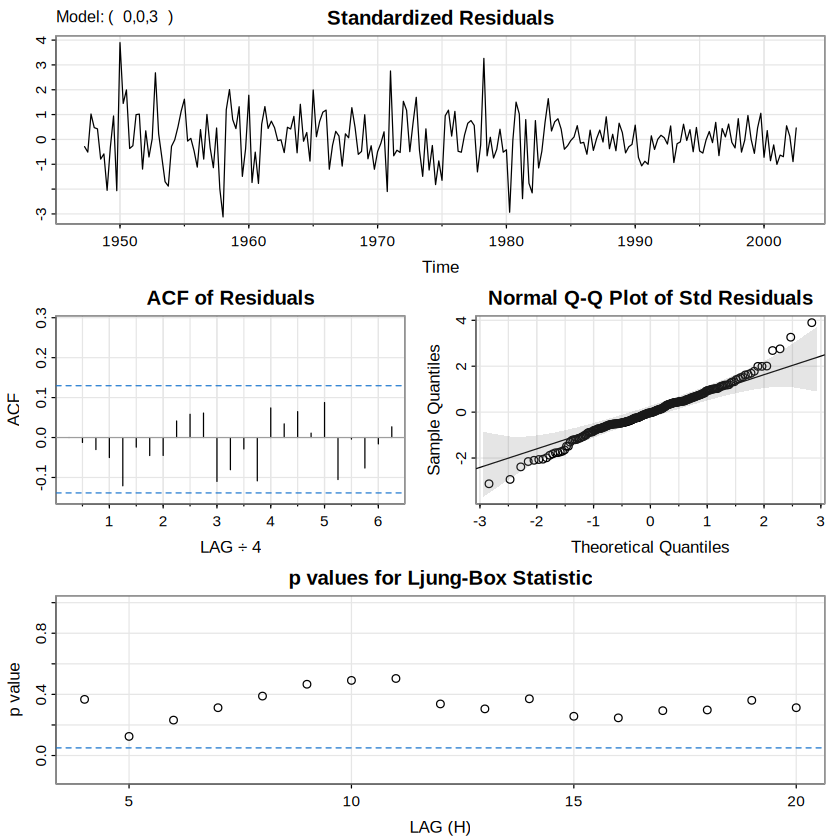

NULL


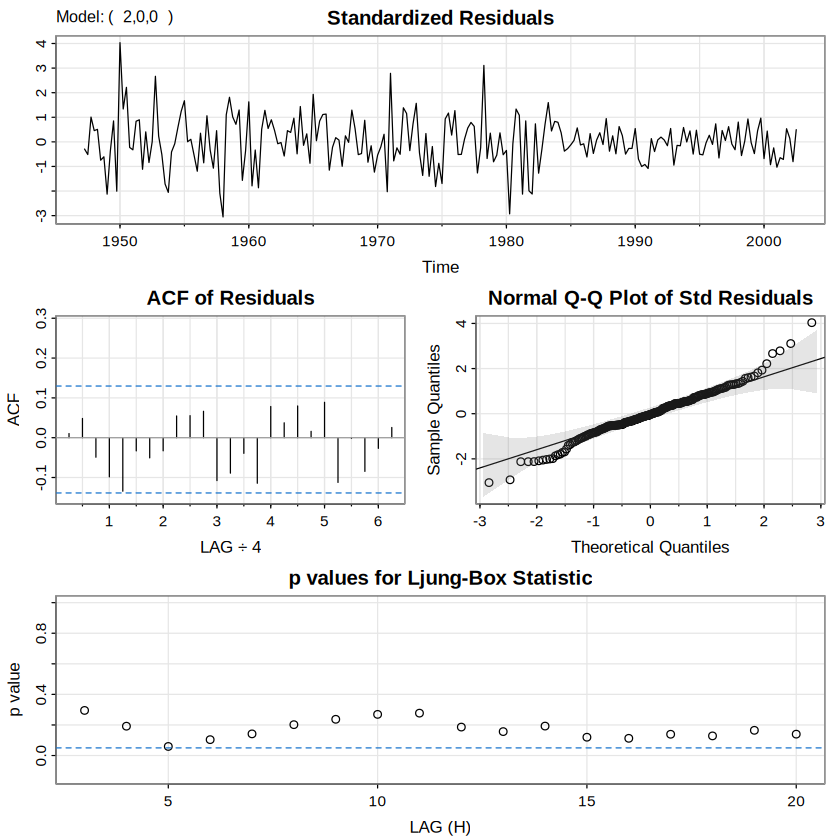

In [8]:
# sarima() draws standardized residual, residual ACF, Q-Q and Ljung-Box plots
sarima(growth, 0,0,2)
# A limited overfitting check: one extra parameter
fit_gnp_ma3 = sarima(growth, 0,0,3)
fit_gnp_ar2 = sarima(growth, 2,0,0)
# Information criteria are comparable only on the same series and likelihood convention.
get_criteria = function(z) c(AIC=z$AIC, AICc=z$AICc, BIC=z$BIC)
print(rbind(AR1=get_criteria(fit_gnp_ar1), MA2=get_criteria(fit_gnp_ma2),
            AR2=get_criteria(fit_gnp_ar2), MA3=get_criteria(fit_gnp_ma3)))

**Interpretation:** The MA(2) fit yields **AIC = −6.4501**, **AICc = −6.4496**, **BIC = −6.3888**; the AR(1) fit yields **−6.4469**, **−6.4467**, **−6.4010**, respectively. AIC/AICc slightly favor MA(2); BIC slightly favors AR(1). The absolute differences are small and neither ranking establishes a substantial forecasting advantage. The added MA(3) coefficient is **0.0909** (p = **0.1963**), and added AR(2) coefficient is **0.0820** (p = **0.2207**), so these additional terms have limited support. In the four diagnostic panels, check residual variation and outliers, ACF spikes, normal Q–Q deviations, and the *sequence* of Ljung–Box p-values. A Ljung–Box p-value above 0.05 means insufficient evidence of residual autocorrelation at those lags, not proof of independence.

### Differencing caution and a deliberately poor extrapolation

**Overdifferencing** can introduce artificial negative lag-1 autocorrelation (e.g., differences of white noise have MA(1) coefficient $-1$ in the simple representation). **Overfitting** adds excessive model flexibility, which can make in-sample error tiny but forecasts unstable. A polynomial of degree eight on a dozen census observations illustrates this failure; it is not a credible forecasting model.

[1] 0.99969
Extrapolated 2024 population in model (millions): -3.3258 


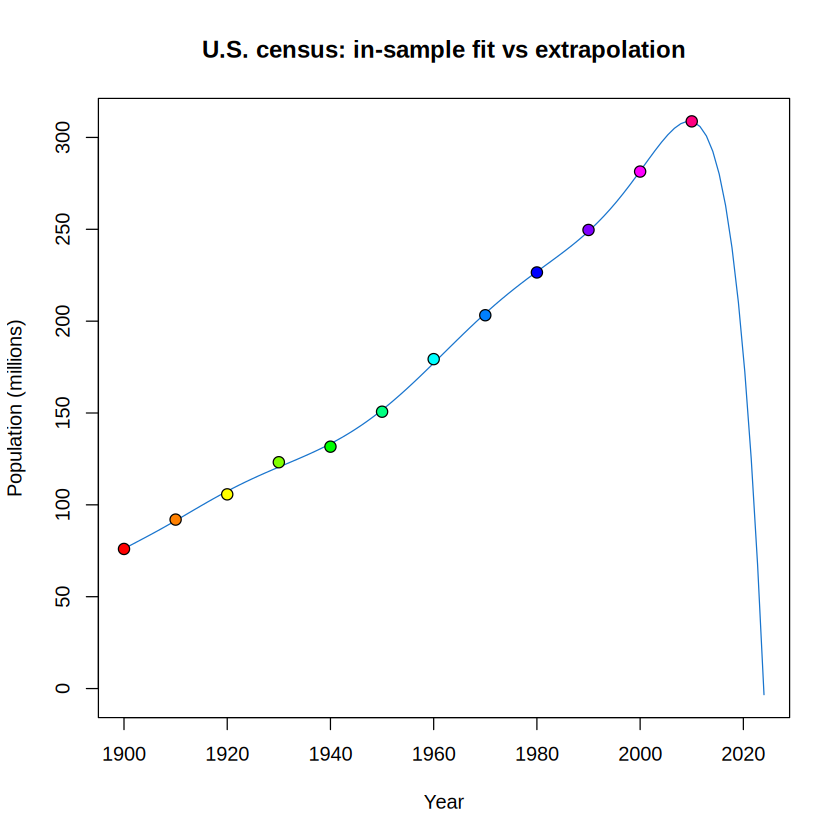

In [9]:
uspop = c(75.995,91.972,105.711,123.203,131.669,150.697,
          179.323,203.212,226.505,249.633,281.422,308.745)
uspop = ts(uspop, start=1900, freq=.1)
t = time(uspop)-1955
reg = lm(uspop ~ t+I(t^2)+I(t^3)+I(t^4)+I(t^5)+I(t^6)+I(t^7)+I(t^8))
print(summary(reg)$r.squared)
b = as.vector(coef(reg))
g = function(t){
  b[1]+b[2]*(t-1955)+b[3]*(t-1955)^2+b[4]*(t-1955)^3+
  b[5]*(t-1955)^4+b[6]*(t-1955)^5+b[7]*(t-1955)^6+
  b[8]*(t-1955)^7+b[9]*(t-1955)^8
}
curve(g, 1900, 2024, ylab="Population (millions)", xlab="Year",
      main="U.S. census: in-sample fit vs extrapolation", col=4)
points(time(uspop), uspop, pch=21, bg=rainbow(12), cex=1.25)
cat("Extrapolated 2024 population in model (millions):",g(2024),"
")

**Interpretation:** The fitted degree-eight polynomial gives $R^2=0.99969$, a near-perfect **in-sample** fit, yet the model's extrapolated population for 2024 is **−3.3258 million**, which is impossible. High-degree polynomial behavior outside the training range makes this forecast unusable. The example distinguishes fitting historical points from forecasting new observations.

## Seasonal ARIMA

A **seasonal period** $s$ is the number of observations per cycle (monthly annual cycle: $s=12$; quarterly annual cycle: $s=4$). The **seasonal difference** compares the same season of adjacent cycles:

$$\nabla_s^D x_t=(1-B^s)^D x_t;\qquad\nabla_{12}x_t=x_t-x_{t-12}.$$

A multiplicative SARIMA model is

$$\Phi_P(B^s)\phi_p(B)(1-B)^d(1-B^s)^D x_t=\alpha+\Theta_Q(B^s)\theta_q(B)w_t,$$

written $\operatorname{ARIMA}(p,d,q)\times(P,D,Q)_s$. Capital $P,D,Q$ refer to **seasonal** orders, while lower-case $p,d,q$ refer to **nonseasonal** orders. The multiplicative form creates cross-lag coefficients as parameter products rather than independent coefficients.

### Pure seasonal AR(1) and MA(1)

$$\text{SAR(1)}_{12}:\quad x_t=\Phi x_{t-12}+w_t,\quad |\Phi|<1,$$

$$\rho(12k)=\Phi^{|k|},\quad \rho(h)=0\ \text{if }h\text{ is not a multiple of }12.$$

$$\text{SMA(1)}_{12}:\quad x_t=w_t+\Theta w_{t-12},\qquad \rho(12)=\frac{\Theta}{1+\Theta^2}.$$

Pure SAR ACF decays at multiples of 12 and PACF cuts off after seasonal lag 1; pure SMA ACF cuts off after seasonal lag 1 and PACF tails off at seasonal multiples. Real mixed series need not show exact cutoffs.

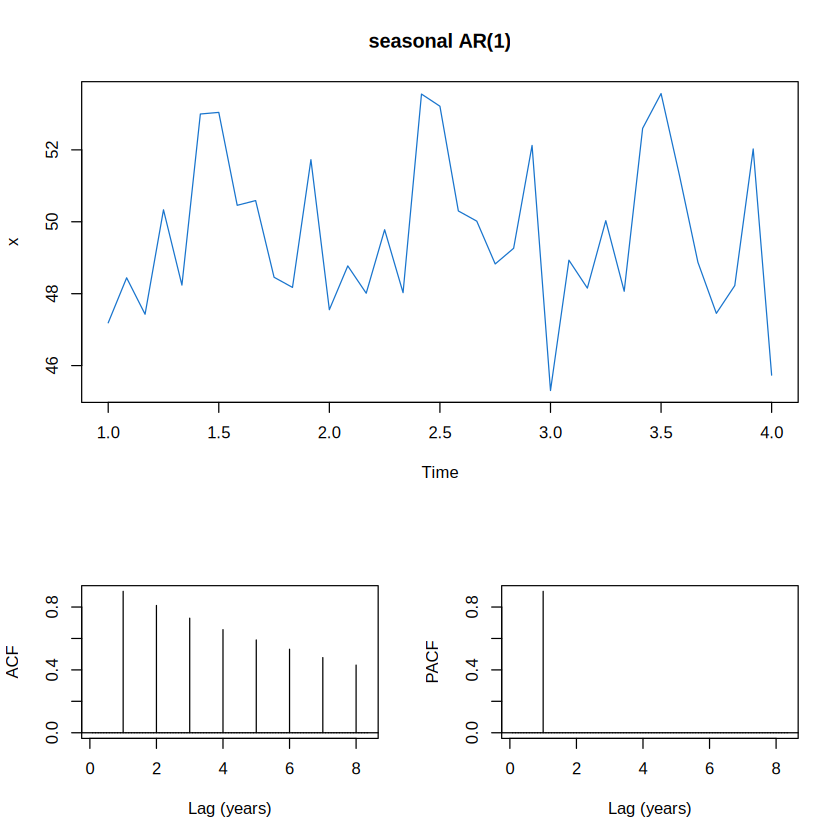

In [10]:
set.seed(666)
phi = c(rep(0,11),.9)
sAR = ts(arima.sim(list(order=c(12,0,0), ar=phi), n=37), freq=12)+50
layout(matrix(c(1,2,1,3), nc=2), heights=c(1.5,1))
plot(sAR, main="seasonal AR(1)", ylab="x", col=4)
ACF = ARMAacf(ar=phi, ma=0, 100)[-1]
PACF = ARMAacf(ar=phi, ma=0, 100, pacf=TRUE)
LAG = (1:100)/12
plot(LAG, ACF, type="h", xlab="Lag (years)", ylab="ACF"); abline(h=0)
plot(LAG, PACF, type="h", xlab="Lag (years)", ylab="PACF"); abline(h=0)
par(mfrow=c(1,1))

**Graph interpretation:** A repeated month-to-same-month relationship creates an ACF spike at lag 12, then lag 24, lag 36, and so on, with decreasing magnitude. The theoretical PACF has its main seasonal spike at lag 12. Because the time series has `frequency=12`, lag 1 on the axes is **one year**, not one month. Added constant 50 shifts the level but does not alter theoretical correlations.

### Mixed seasonal process and seasonal persistence

For $x_t=\Phi x_{t-12}+w_t+\theta w_{t-1}$, the MA(1) within-season and seasonal AR(1) terms interact. **Seasonal persistence** means values tend to recur across cycles; a slow ACF decline at lag $s,2s,3s,\ldots$ suggests considering $D=1$ seasonal differencing before fitting a stationary model.

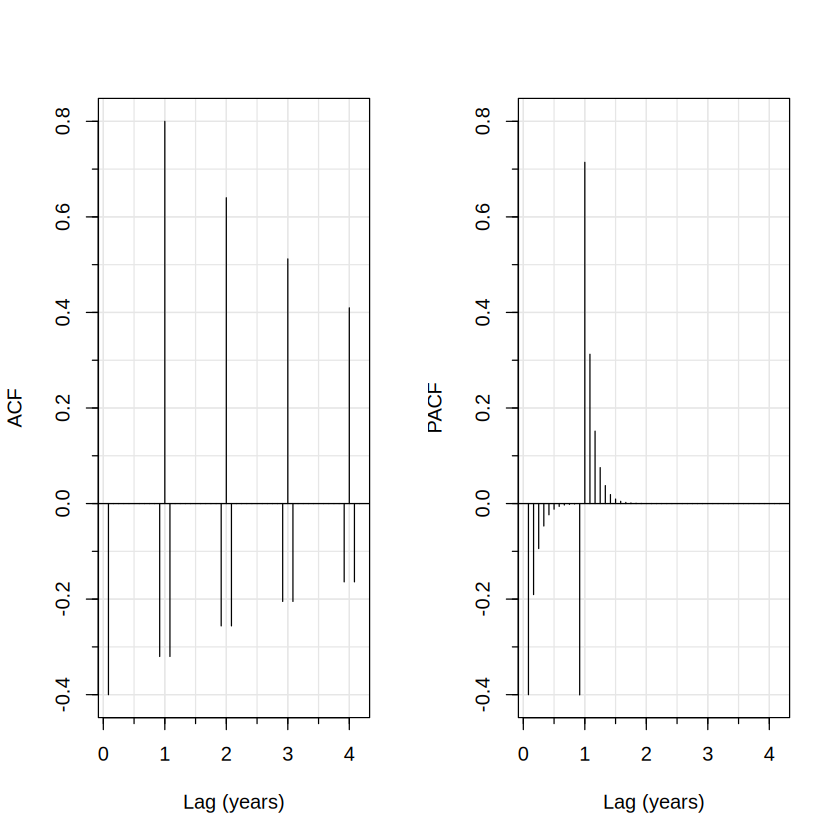

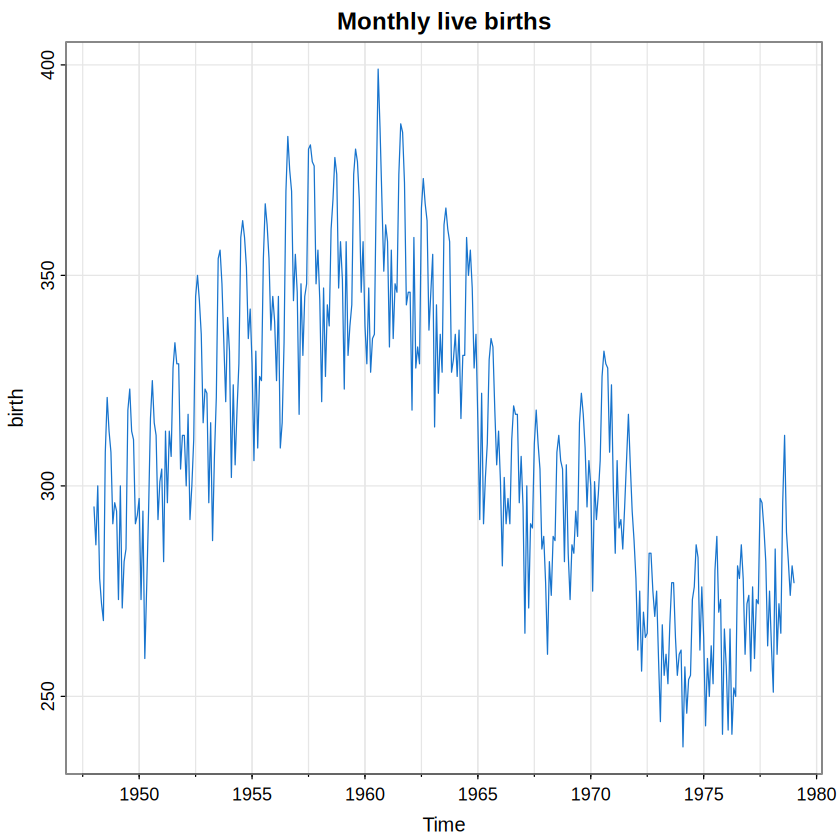

ACF,-0.32,0.16,-0.08,-0.19,0.09,-0.28,0.06,-0.19,-0.05,0.17,⋯,-0.08,-0.15,0.05,-0.25,0.06,-0.18,-0.03,0.15,-0.22,0.72
PACF,-0.32,0.06,-0.01,-0.25,-0.03,-0.26,-0.17,-0.29,-0.35,-0.16,⋯,-0.03,0.07,-0.04,0.06,0.04,-0.07,-0.06,0.02,-0.04,0.10


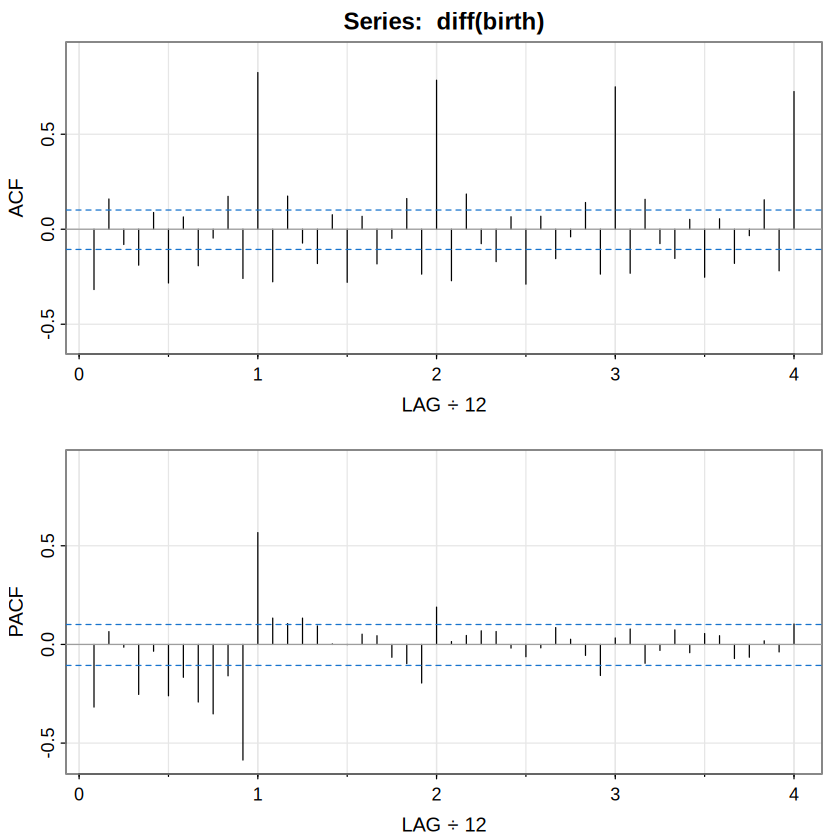

In [11]:
phi = c(rep(0,11),.8)
ACF = ARMAacf(ar=phi, ma=-.5, 50)[-1]
PACF = ARMAacf(ar=phi, ma=-.5, 50, pacf=TRUE)
LAG = (1:50)/12
par(mfrow=c(1,2))
plot(LAG, ACF, type="h", ylim=c(-.4,.8), xlab="Lag (years)", panel.first=Grid())
abline(h=0)
plot(LAG, PACF, type="h", ylim=c(-.4,.8), xlab="Lag (years)", panel.first=Grid())
abline(h=0)
par(mfrow=c(1,1))
tsplot(birth, col=4, main="Monthly live births")
acf2(diff(birth))

**Interpretation:** In the theoretical mixed seasonal model, $\theta=-0.5$ introduces negative dependence at short lags, while $\Phi=0.8$ produces positive correlation at annual lags. Compare the theoretical ACF/PACF with `acf2(diff(birth))`, where one year corresponds to 12 monthly observations. Similar patterns suggest candidate orders but cannot establish the best model without estimating parameters and checking residuals.

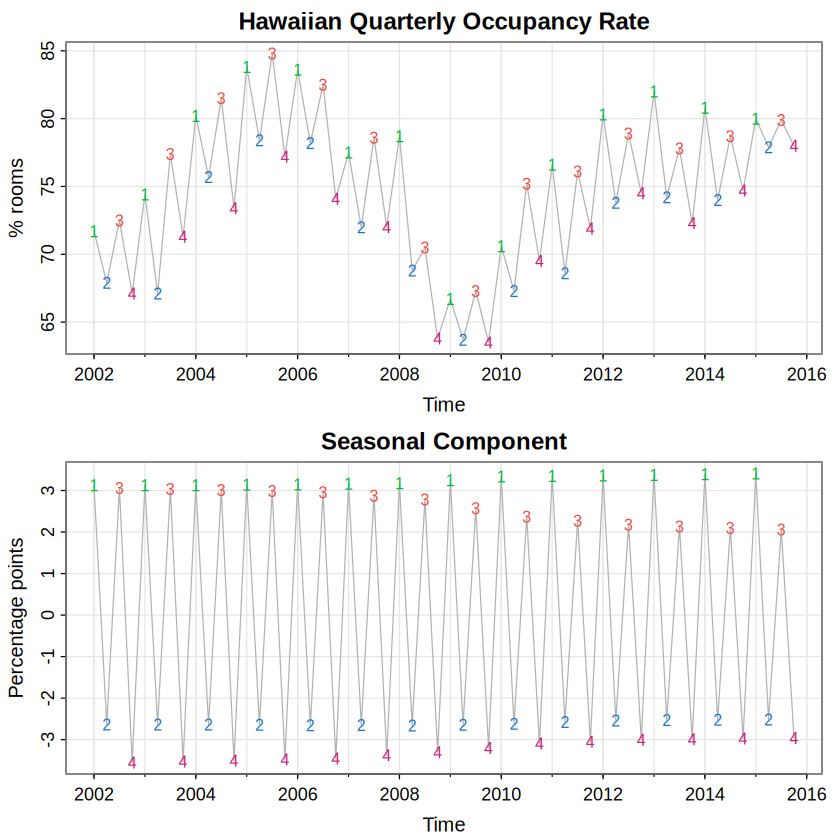

In [12]:
x_hor = window(hor, start=2002)
par(mfrow=c(2,1))
tsplot(x_hor, main="Hawaiian Quarterly Occupancy Rate", ylab="% rooms", col=gray(.7))
text(x_hor, labels=1:4, col=c(3,4,2,6), cex=.8)
Qx = stl(x_hor, s.window=15)$time.series[,1]
tsplot(Qx, main="Seasonal Component", ylab="Percentage points", col=gray(.7))
text(Qx, labels=1:4, col=c(3,4,2,6), cex=.8)
par(mfrow=c(1,1))

**Interpretation:** Seasonal component values above zero represent a positive occupancy contribution in **percentage points**, not percentage growth. Repeated highs/lows in the same quarter support seasonal persistence. The extracted component comes from STL and is an estimate, not a uniquely determined physical signal; changing the smoothing window can change it.

### Multiplicative seasonal MA example

For $\operatorname{ARIMA}(0,1,1)\times(0,1,1)_{12}$ with zero constant,

$$ (1-B)(1-B^{12})x_t=(1+\theta B)(1+\Theta B^{12})w_t.$$

Expansion gives

$$x_t=x_{t-1}+x_{t-12}-x_{t-13}+w_t+\theta w_{t-1}+\Theta w_{t-12}+\theta\Theta w_{t-13}.$$

The lag-13 coefficient $\theta\Theta$ is **not** estimated as a separate parameter. This restriction keeps the seasonal model parsimonious.

## Atmospheric CO₂: transformation, fit, diagnostics and forecast

Here `cardox` is monthly CO₂ concentration in parts per million (**ppm**). **Nonseasonal difference** $x_t-x_{t-1}$ removes much of the growth pattern; **seasonal difference** $x_t-x_{t-12}$ reduces regular annual seasonality. Inspect the doubly differenced observations and ACF/PACF before choosing orders.

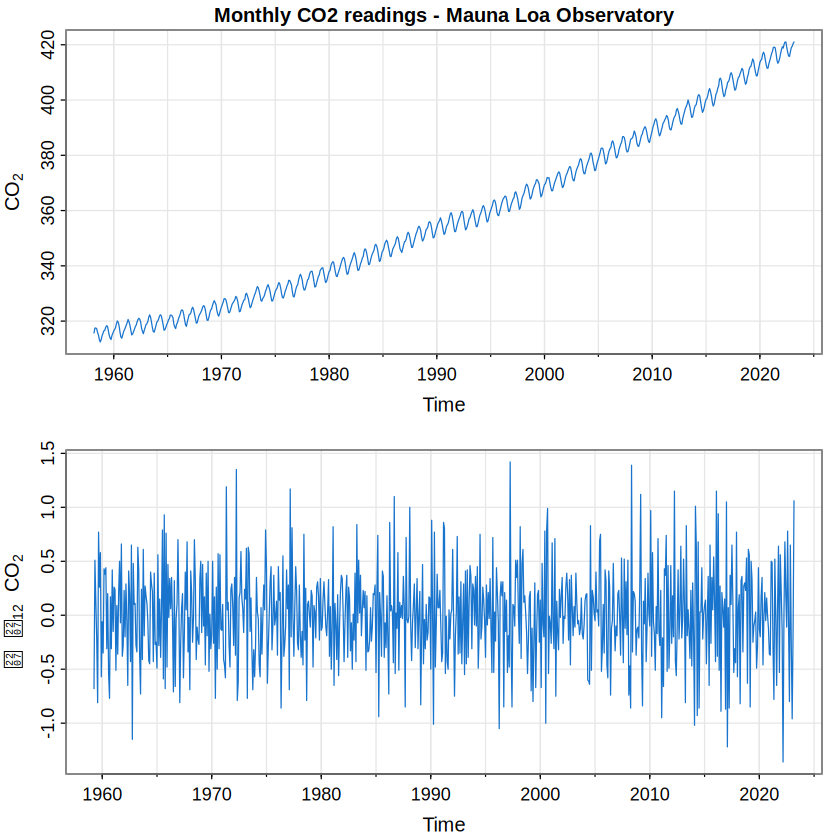

ACF,-0.3,-0.03,-0.06,0.00,0.00,-0.01,0.03,-0.01,0.05,-0.03,⋯,-0.01,-0.01,-0.01,-0.03,0.03,0.03,-0.05,0,0.02,-0.02
PACF,-0.3,-0.13,-0.12,-0.07,-0.04,-0.03,0.02,0.01,0.07,0.02,⋯,-0.02,-0.06,-0.03,-0.04,-0.11,0.02,-0.05,0,0.07,-0.14


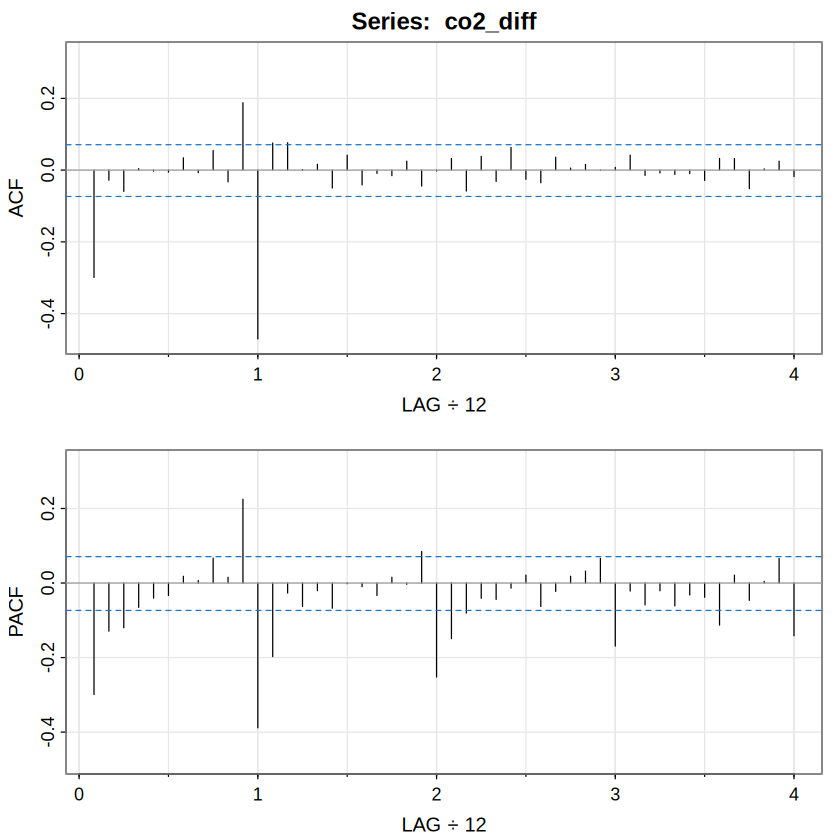

In [13]:
par(mfrow=c(2,1))
tsplot(cardox, col=4, ylab=expression(CO[2]))
title("Monthly CO2 readings - Mauna Loa Observatory", cex.main=1)
co2_diff = diff(diff(cardox, 12))
tsplot(co2_diff, col=4, ylab=expression(nabla~nabla[12]~CO[2]))
par(mfrow=c(1,1))
acf2(co2_diff)

**Graph interpretation:** The raw data exhibit both increasing levels and regular annual swings. Successful combined differencing should remove most of these visible patterns, although remaining autocorrelation may require AR or MA terms. The ACF at seasonal lags is reported in *years* for frequency-12 data. A lag-1 seasonal feature is at 12 observations, not one observation.

initial  value -0.826338 
iter   2 value -1.059073
iter   3 value -1.093845
iter   4 value -1.116555
iter   5 value -1.124382
iter   6 value -1.126345
iter   7 value -1.127354
iter   8 value -1.127953
iter   9 value -1.127984
iter  10 value -1.127985
iter  10 value -1.127985
iter  10 value -1.127985
final  value -1.127985 
converged
initial  value -1.144615 
iter   2 value -1.148048
iter   3 value -1.148645
iter   4 value -1.149895
iter   5 value -1.150013
iter   6 value -1.150021
iter   7 value -1.150021
iter   7 value -1.150021
iter   7 value -1.150021
final  value -1.150021 
converged
<><><><><><><><><><><><><><>
 
Coefficients: 
     Estimate     SE t.value p.value
ma1   -0.3869 0.0377 -10.262       0
sma1  -0.8655 0.0183 -47.285       0

sigma^2 estimated as 0.098091 on 766 degrees of freedom 
 
AIC = 0.54565  AICc = 0.54567  BIC = 0.56379 
 
initial  value -0.827261 
iter   2 value -1.034332
iter   3 value -1.066295
iter   4 value -1.094823
iter   5 value -1.108013
iter   6 value

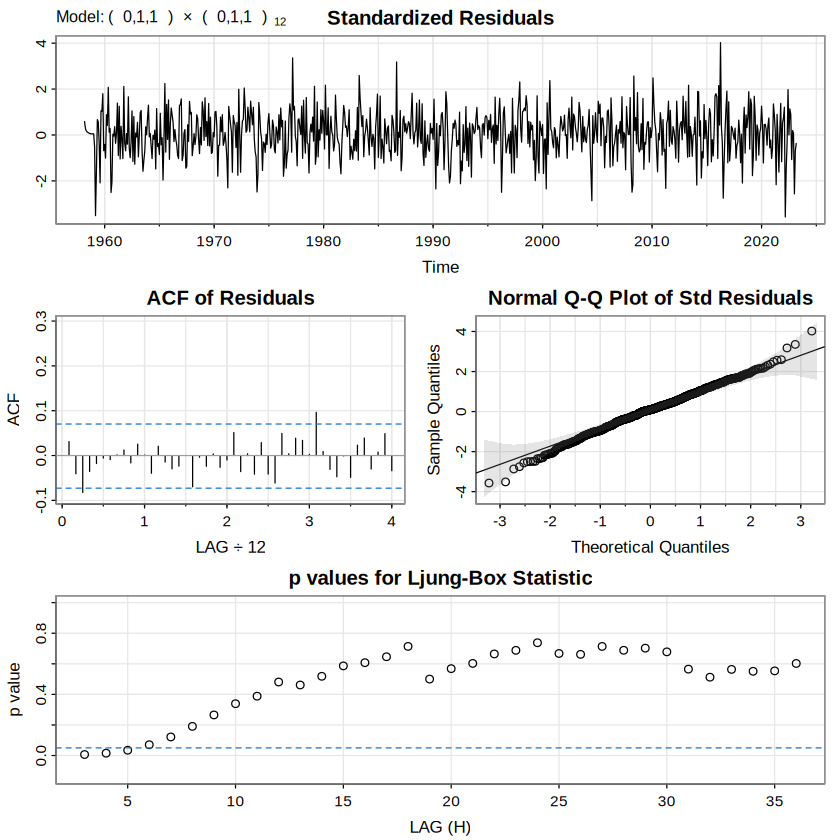

NULL
     ma1     sma1 
-0.38685 -0.86554 
     ar1      ma1     sma1 
 0.22034 -0.57973 -0.86565 


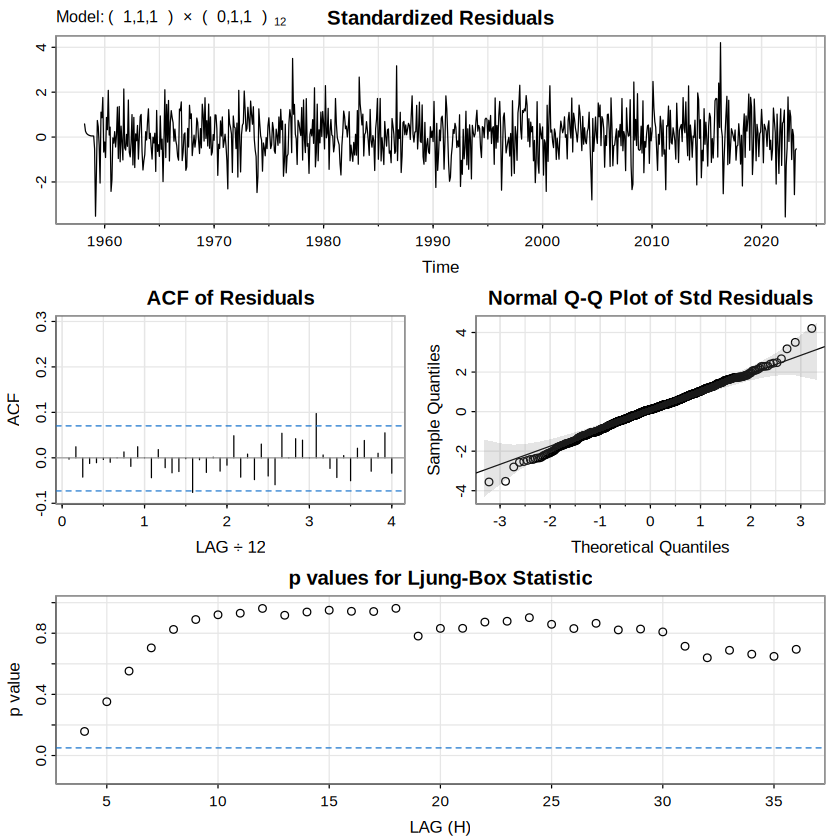

In [14]:
co2_011_011 = sarima(cardox, p=0,d=1,q=1, P=0,D=1,Q=1,S=12)
co2_111_011 = sarima(cardox, p=1,d=1,q=1, P=0,D=1,Q=1,S=12)
print(rbind(first=get_criteria(co2_011_011), second=get_criteria(co2_111_011)))
print(co2_011_011$fit$coef)
print(co2_111_011$fit$coef)

**Interpretation:** The executed ARIMA(0,1,1) $\times$ (0,1,1)$_{12}$ model estimates $\hat\theta=-0.3869$ (SE **0.0377**) and $\hat\Theta=-0.8655$ (SE **0.0183**), with $\hat\sigma_w^2=0.098091$. Adding nonseasonal AR(1) gives $\hat\phi=0.2203$ (SE **0.0894**, p = **0.0139**), $\hat\theta=-0.5797$, $\hat\Theta=-0.8656$, and variance **0.097428**. The complex model has lower **AIC (0.54151 versus 0.54565)** and **AICc (0.54155 versus 0.54567)**, while the simpler model has lower **BIC (0.56379 versus 0.56570)**. These measures give a close, mixed ranking; inspect the residual plots and practical forecast differences. The coefficients describe time-series dependence, not the physical causes of CO₂ growth.

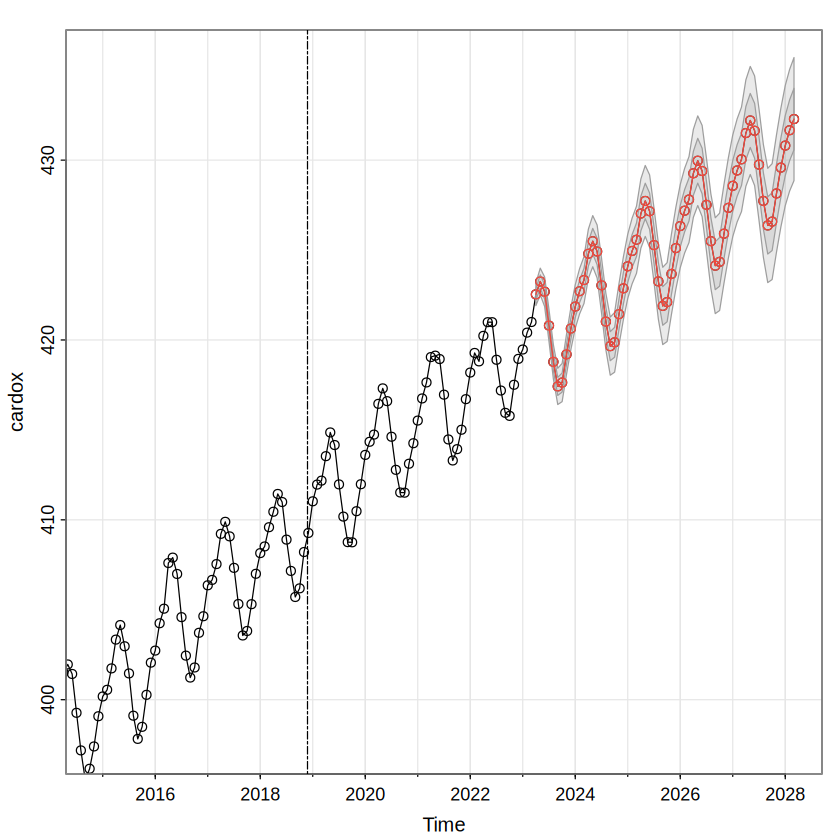

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2023,,,,422.49,423.19,422.62,420.73,418.72,417.35,417.57,419.13,420.57
2024,421.79,422.65,423.27,424.72,425.42,424.85,422.96,420.95,419.58,419.80,421.36,422.80
2025,424.02,424.88,425.50,426.95,427.65,427.07,425.19,423.17,421.81,422.02,423.59,425.03
2026,426.25,427.10,427.72,429.18,429.87,429.30,427.42,425.40,424.04,424.25,425.82,427.25
2027,428.48,429.33,429.95,431.41,432.10,431.53,429.65,427.63,426.27,426.48,428.05,429.48
2028,430.71,431.56,432.18,,,,,,,,,
,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2023,,,,0.31319,0.36738,0.41454,0.45686,0.49558,0.53149,0.56511,0.59685,0.62698
2024,0.65573,0.68327,0.70975,0.74737,0.77848,0.80839,0.83723,0.86511,0.89212,0.91833,0.94382,0.96863
2025,0.99283,1.01645,1.03954,1.07155,1.09891,1.12560,1.15167,1.17717,1.20213,1.22658,1.25055,1.27407


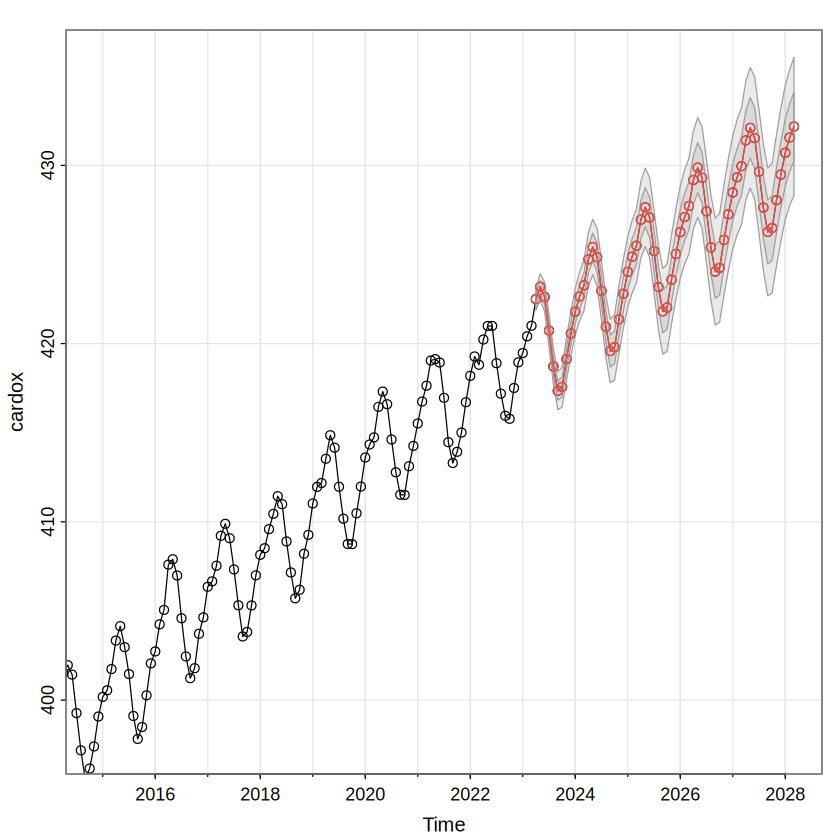

In [15]:
co2_forecast = sarima.for(cardox, 60, 1,1,1, 0,1,1,12)
abline(v=2018.9, lty=6)
# For a side-by-side specification check, generate the simpler model separately.
sarima.for(cardox, 60, 0,1,1, 0,1,1,12)

**Forecast interpretation:** The first chart forecasts **60 months (five years)** from the fitted ARIMA(1,1,1) $\times$ (0,1,1)$_{12}$; the second uses the simpler ARIMA(0,1,1) $\times$ (0,1,1)$_{12}$. Both continue an upward mean trajectory with annual fluctuations, and forecast uncertainty broadens with horizon. Compare the curves and their interval widths; these are model-conditional forecasts from the **historical dataset**, not current real-time CO₂ measurements or guarantees about future emissions.

## Regression with autocorrelated errors

When regression errors are serially correlated, standard OLS coefficients can still describe fitted linear associations, but standard OLS uncertainty calculations may be wrong. A regression with ARMA errors models the dependence directly:

$$y_t=\beta_0+\sum_{j=1}^{r}\beta_jz_{tj}+x_t,\qquad\phi(B)x_t=\theta(B)w_t.$$

For AR(1) errors $x_t=\phi x_{t-1}+w_t$, applying $(1-\phi B)$ to both sides produces

$$y_t-\phi y_{t-1}=(1-\phi)\beta_0+\beta_1(z_t-\phi z_{t-1})+w_t.$$

The $\beta_1$ slope is retained but the intercept becomes $(1-\phi)\beta_0$. Practical fitting uses numerical likelihood estimation; residual ACF/PACF help choose the error order.

### Mortality, temperature and pollution

Centered temperature is $T_t^*=T_t-\overline T$, and the model includes both $T_t^*$ and $(T_t^*)^2$ to allow a curved mortality–temperature relationship. **Centering** reduces collinearity and changes the meaning of the linear term: it is the local slope near average temperature. The quadratic coefficient controls curvature.

ACF,0.34,0.44,0.28,0.28,0.16,0.12,0.07,0.01,0.03,-0.05,⋯,-0.04,0.05,0.00,0.04,0.08,0.07,0.06,0.05,0.07,0.02
PACF,0.34,0.36,0.08,0.06,-0.05,-0.05,-0.02,-0.05,0.02,-0.06,⋯,-0.01,0.08,-0.01,-0.01,0.08,-0.01,-0.01,-0.03,0.03,-0.04


initial  value 1.849900 
iter   2 value 1.733730
iter   3 value 1.701063
iter   4 value 1.682463
iter   5 value 1.657377
iter   6 value 1.652444
iter   7 value 1.641726
iter   8 value 1.635302
iter   9 value 1.630848
iter  10 value 1.629286
iter  11 value 1.628731
iter  12 value 1.628646
iter  13 value 1.628634
iter  14 value 1.628633
iter  15 value 1.628632
iter  16 value 1.628628
iter  17 value 1.628627
iter  18 value 1.628627
iter  19 value 1.628626
iter  20 value 1.628625
iter  21 value 1.628622
iter  22 value 1.628618
iter  23 value 1.628614
iter  24 value 1.628612
iter  25 value 1.628611
iter  26 value 1.628610
iter  27 value 1.628610
iter  28 value 1.628609
iter  29 value 1.628609
iter  30 value 1.628608
iter  31 value 1.628608
iter  32 value 1.628608
iter  32 value 1.628608
iter  32 value 1.628608
final  value 1.628608 
converged
initial  value 1.630401 
iter   2 value 1.630393
iter   3 value 1.630382
iter   4 value 1.630381
iter   5 value 1.630375
iter   6 value 1.630370
iter 

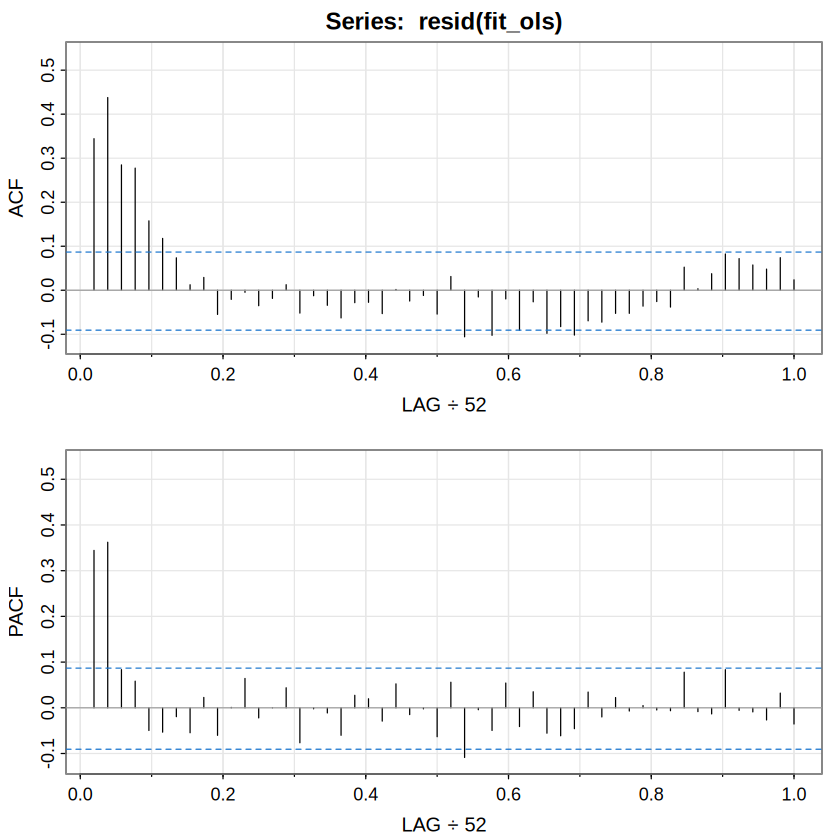

        ar1         ar2   intercept       trend        temp       temp2 
   0.384786    0.432620 3075.148212   -1.516520   -0.018983    0.015427 
       part 
   0.154460 


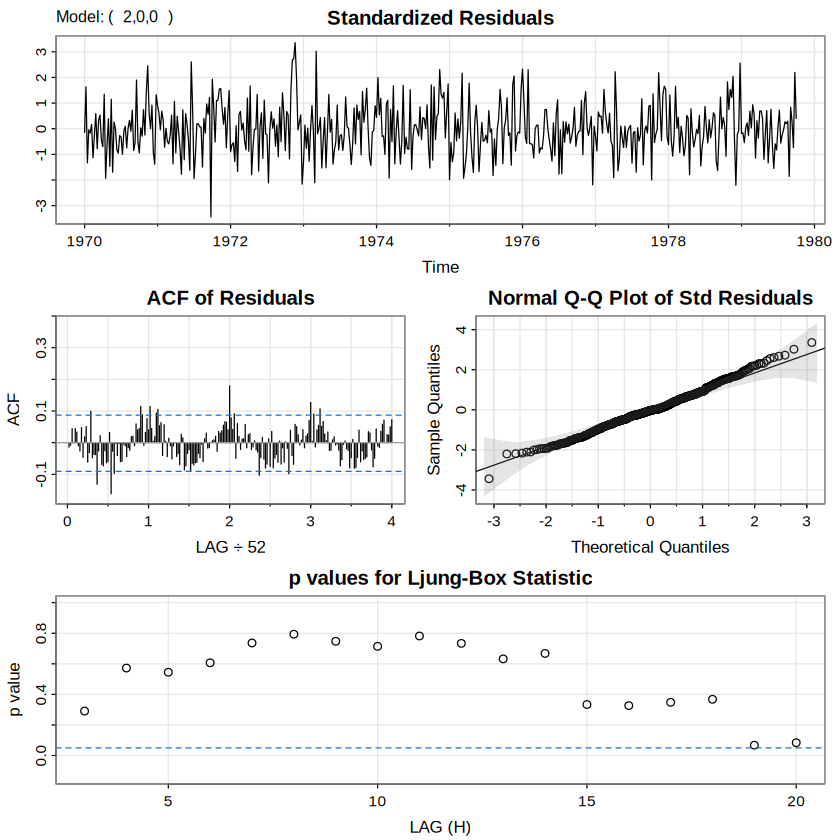

In [16]:
trend = time(cmort)
temp = tempr-mean(tempr)
temp2 = temp^2
fit_ols = lm(cmort ~ trend + temp + temp2 + part, na.action=NULL)
acf2(resid(fit_ols), 52)
fit_mort_ar2 = sarima(cmort, 2,0,0, xreg=cbind(trend,temp,temp2,part))
print(fit_mort_ar2$fit$coef)

**Interpretation:** The executed regression with AR(2) errors gives $\hat\phi_1=0.3848$, $\hat\phi_2=0.4326$; the centered-temperature linear term is **−0.0190** (SE **0.0495**, p = **0.7014**), while the quadratic term is **+0.01543** (SE **0.0020**, p reported as 0.0000), and particulate term is **+0.15446** (SE **0.0272**). The linear temperature coefficient is the local temperature slope at the sample mean temperature; its nonsignificance does **not** remove the curved temperature association. At fixed time and other regressors, the positive pollutant coefficient represents higher predicted mortality with higher particulates, not proof of causation. The fitted innovation variance **26.015** is the residual shock variance under the AR(2) model. Interpret inference with the residual diagnostic panels.

### Lagged hare–lynx regression with AR(2) errors

A **leading indicator** is an earlier observation used to help predict a later one. The model

$$L_t=\beta_0+\beta_1H_{t-1}+x_t,\qquad x_t=\phi_1x_{t-1}+\phi_2x_{t-2}+w_t$$

relates this year's lynx measure $L_t$ to last year's hare measure $H_{t-1}$ while modeling serial dependence in regression errors. Check the lagged alignment before interpreting forecasts.

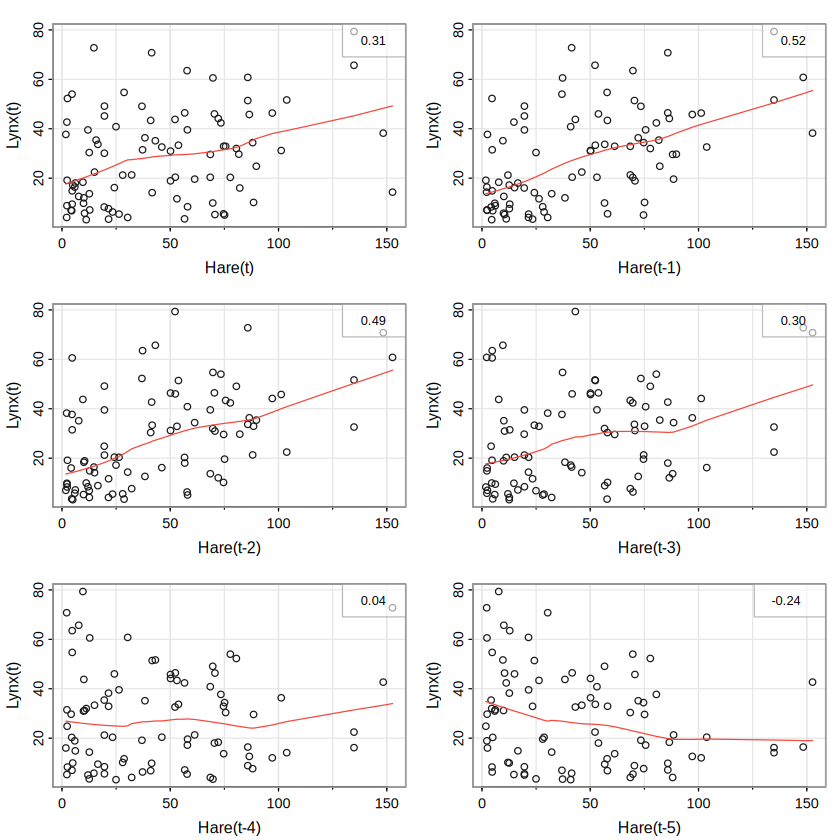

ACF,0.73,0.30,-0.10,-0.35,-0.48,-0.43,-0.21,0.03,0.21,0.28,0.27,0.09,-0.16,-0.32,-0.35,-0.26,-0.10,0.14,0.34,0.37
PACF,0.73,-0.52,-0.18,-0.05,-0.25,0.08,0.13,-0.08,0.04,0.03,0.00,-0.24,-0.10,0.07,-0.13,0.04,0.06,0.08,0.05,-0.10


initial  value 2.758050 
iter   2 value 2.608114
iter   3 value 2.338840
iter   4 value 2.248812
iter   5 value 2.046836
iter   6 value 2.045593
iter   7 value 2.045218
iter   8 value 2.045114
iter   9 value 2.045060
iter  10 value 2.045055
iter  11 value 2.045055
iter  12 value 2.045055
iter  13 value 2.045055
iter  13 value 2.045055
iter  13 value 2.045055
final  value 2.045055 
converged
initial  value 2.056766 
iter   2 value 2.056665
iter   3 value 2.056583
iter   4 value 2.056581
iter   5 value 2.056580
iter   6 value 2.056580
iter   6 value 2.056580
iter   6 value 2.056580
final  value 2.056580 
converged
<><><><><><><><><><><><><><>
 
Coefficients: 
          Estimate     SE t.value p.value
ar1         1.3258 0.0732 18.1184  0.0000
ar2        -0.7143 0.0731 -9.7689  0.0000
intercept  25.1319 2.5469  9.8676  0.0000
xreg        0.0692 0.0318  2.1727  0.0326

sigma^2 estimated as 59.571 on 86 degrees of freedom 
 
AIC = 7.0621  AICc = 7.0674  BIC = 7.201 
 


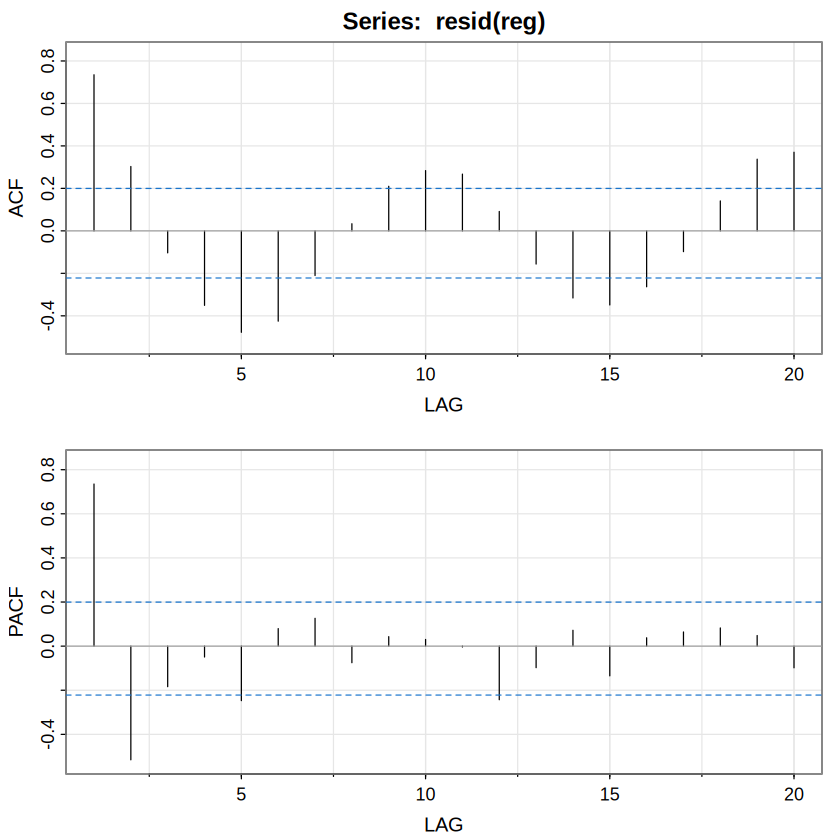

      ar1       ar2 intercept      xreg 
 1.325793 -0.714332 25.131856  0.069155 


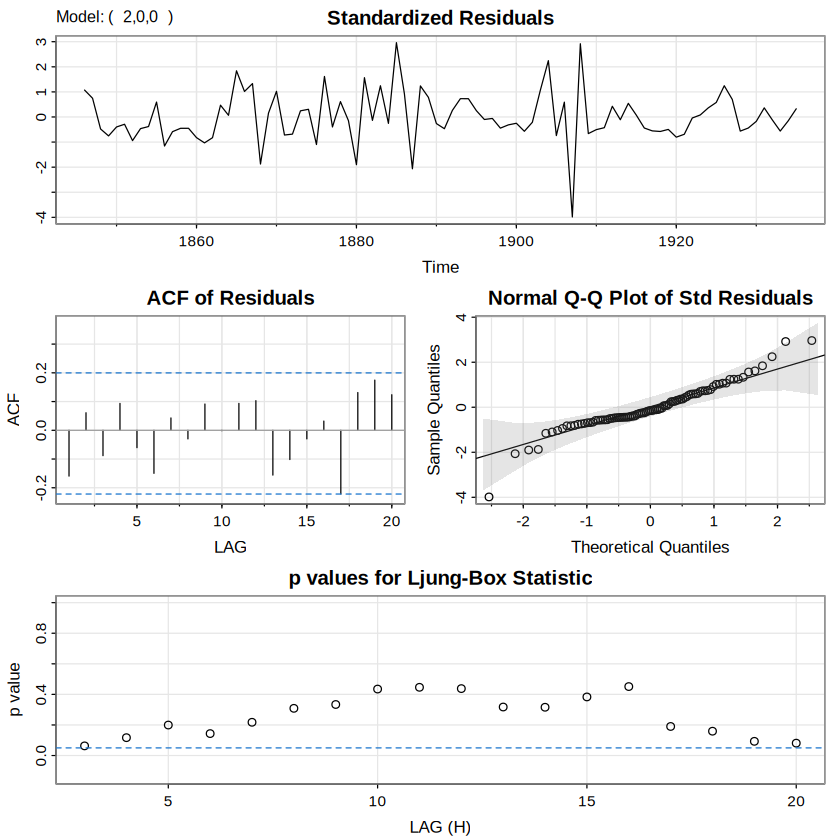

In [17]:
lag2.plot(Hare, Lynx, 5)
pp = as.zoo(ts.intersect(Lynx, HareL1=lag(Hare,-1)))
reg = lm(pp$Lynx ~ pp$HareL1)
acf2(resid(reg))
reg2 = sarima(pp$Lynx, 2,0,0, xreg=pp$HareL1)
print(reg2$fit$coef)

**Interpretation:** The fitted lagged-hare coefficient is **+0.069155** (SE **0.0318**, p = **0.0326**) after modeling AR(2) error dependence, suggesting a positive one-year-lag association in the fitted sample. The AR error estimates $\hat\phi_1=1.3258$ and $\hat\phi_2=-0.7143$ capture oscillatory residual dependence, and the innovation variance is **59.571**. These estimates show association, not a demonstrated causal effect. Prediction accuracy should be judged separately from coefficient significance.

Aligned in-sample one-step RMSE: 7.7182 


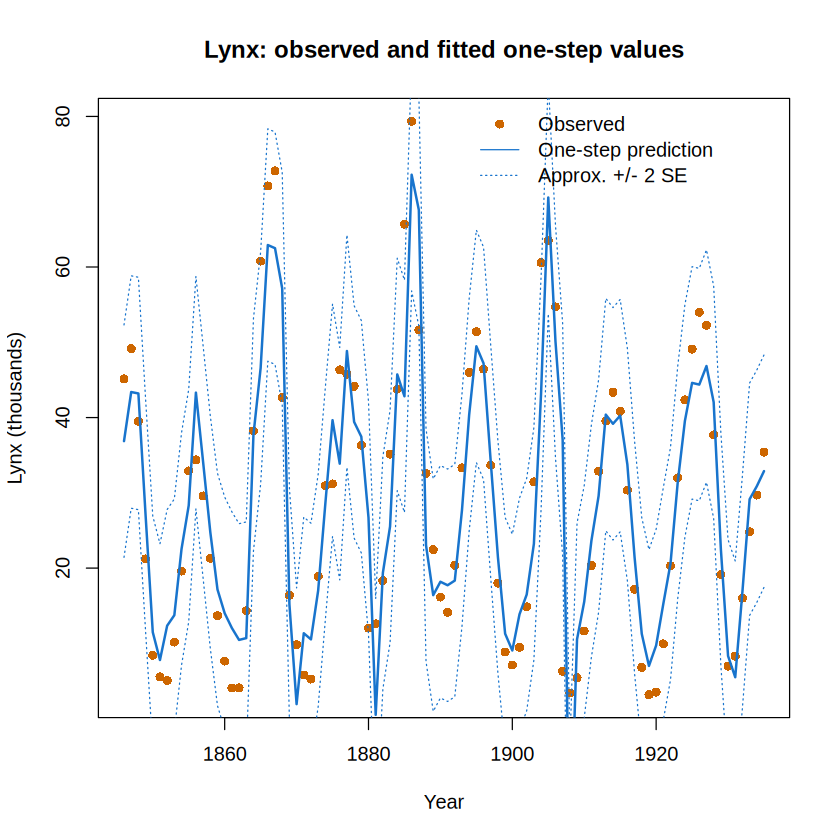

In [18]:
# one-step fitted-value reconstruction; align prediction and observation indices.
lynx_obs = as.numeric(pp$Lynx)
lynx_resid = as.numeric(resid(reg2$fit))
stopifnot(length(lynx_obs)==length(lynx_resid))
lynx_pred = lynx_obs-lynx_resid
lynx_sigma = sqrt(reg2$fit$sigma2)
lynx_time = as.numeric(time(pp$Lynx))
plot(lynx_time, lynx_obs, type="p", pch=16, col="darkorange3",
     xlab="Year", ylab="Lynx (thousands)", main="Lynx: observed and fitted one-step values")
lines(lynx_time, lynx_pred, col=4, lwd=2)
lines(lynx_time, lynx_pred-2*lynx_sigma, lty=3, col=4)
lines(lynx_time, lynx_pred+2*lynx_sigma, lty=3, col=4)
legend("topright", legend=c("Observed","One-step prediction","Approx. +/- 2 SE"),
       pch=c(16,NA,NA), lty=c(NA,1,3), col=c("darkorange3",4,4), bty="n")
cat("Aligned in-sample one-step RMSE:",sqrt(mean((lynx_obs-lynx_pred)^2, na.rm=TRUE)),"
")

**Interpretation:** Observed lynx values are points, and the fitted one-step prediction is the line. The calculated aligned **in-sample RMSE is 7.7182** in the series' displayed scale (thousands). The shaded band is approximately $\pm2\sqrt{59.571}$, or $\pm15.44$ around fitted one-step predictions, using estimated innovation variability; it is not a full parameter-uncertainty interval. The prediction quality shown here is conditional on the fitted model and observed past information, not an independent holdout forecast.

---

**Reference:** Shumway, R. H., & Stoffer, D. S. (2019). *Time Series: A Data Analysis Approach Using R*. Chapman & Hall/CRC Press.